## 🏗️ Heavy Industrial Machinery — Price Prediction
## MLP Kaggle Competition | Complete ML Pipeline

**Problem:** Predict `TargetValue` (auction sale price in USD) of heavy machinery  
**Metric:** RMSLE ≤ **0.15** (Root Mean Squared Logarithmic Error)  
**Data:** 138 701 train rows | 15 000 test rows | 50 features

---
`Load` → `EDA` → `Preprocessing` → `Feature Eng.` → `Models` → `HPT` → `Error Analysis` → `Submit`


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


## Step 1 — Load All Libraries

### What is happening here?
All Python tools needed for this entire machine learning pipeline are loaded in one place.

### Key Libraries:
- **NumPy & Pandas** — Fast math and data table manipulation (like Python Excel)
- **Matplotlib & Seaborn** — For creating charts and visualizations
- **Scikit-learn** — Provides ML algorithms, data splitting, preprocessing, and metrics
- **XGBoost** — Highly accurate gradient boosting model (our final choice!)
- **LightGBM** — Very fast gradient boosting model (close second)
- **SEED = 42** — Fixes randomness so every run gives identical results

### Expected output:
No printed output (libraries are silently loaded)

## 📚 Cell: Load All Libraries

> **What is happening:** We open our toolbox — import every Python package we'll need for this entire notebook.

**🔑 Key observations:**
- We use **5 different model families** in this notebook (Ridge, Random Forest, HistGB, XGBoost, LightGBM). Each one needs its own import.
- `sklearn.pipeline.Pipeline` and `ColumnTransformer` let us chain preprocessing + model in one object.
- `SEED = 42` is the "magic number" that makes all random operations reproducible — same seed → same results every time.
- `warnings.filterwarnings('ignore')` suppresses non-critical warnings to keep output clean.

**Expected output:**
```
✅ All libraries loaded!
   NumPy 2.4.6 | Pandas 2.3.3
```


In [3]:
# ══════════════════════════════════════════════════════
# 1.  SETUP & IMPORTS
# ══════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import warnings, os
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import missingno as msno

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid', palette='Set2')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score, make_scorer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.dummy import DummyRegressor
from xgboost import XGBRegressor
import lightgbm as lgb

SEED = 42
np.random.seed(SEED)
print("✅ All libraries loaded!")
print(f"   NumPy {np.__version__} | Pandas {pd.__version__}")


✅ All libraries loaded!
   NumPy 2.4.6 | Pandas 2.3.3


## Step 2 — Load the Competition Data

### What is happening here?
All four competition files are loaded into Python memory.

### Data Overview:
| File | Rows | Columns | Purpose |
|------|------|---------|---------|
| `train.csv` | 138,701 | 50 | Historical auctions **with** actual prices |
| `test.csv` | 15,000 | 49 | Auctions **without** prices — we predict these |
| `sample_submission.csv` | 15,000 | 2 | Format template for submission |
| `metadata.csv` | varies | — | Column descriptions |

### Key Observation:
- Train has **50 columns**, Test has **49** — the missing column is `TargetValue` (the price we must predict!)
- Both datasets contain heavy equipment auction data from auctions across different US regions

## 📂 Cell: Load Competition Data

> **What is happening:** Reads all 4 competition files from Kaggle's cloud storage into Python memory.

**🔑 Key observations:**
- `train.csv` → 138,701 rows × 50 cols — historical auctions WITH actual prices (`TargetValue`)
- `test.csv` → 15,000 rows × 49 cols — auctions WITHOUT prices (we predict these!)
- `sample_submission.csv` → shows the format Kaggle expects: just 2 columns (`TransactionID`, `TargetValue`)
- `metadata.csv` → additional column descriptions

**⚠️ Warning:** Paths `/kaggle/input/...` only exist on Kaggle. Running locally will fail with FileNotFoundError.

**Expected output:**
```
============================================================
  DATA LOADING COMPLETE
============================================================
  train_df : 138,701 rows × 50 columns
  test_df  :  15,000 rows × 49 columns
```


In [4]:
# ══════════════════════════════════════════════════════
# 2.  DATA LOADING
# ══════════════════════════════════════════════════════
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv')
test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv')
sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')
metadata = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv')

print("=" * 60)
print(f"  TRAIN   : {train_df.shape[0]:,} rows × {train_df.shape[1]} cols")
print(f"  TEST    : {test_df.shape[0]:,}  rows × {test_df.shape[1]} cols")
print(f"  SAMPLE  : {sample.shape}")
print("=" * 60)

print("\nRequired submission format:")
display(sample.head(3))
print("\nColumn descriptions (metadata):")
print(metadata[['Variable','Rephrased Description']].to_string(index=False))


  TRAIN   : 138,701 rows × 50 cols
  TEST    : 15,000  rows × 49 cols
  SAMPLE  : (15000, 2)

Required submission format:


,TransactionID,TargetValue
0,1139307,44674.90
1,1139419,91450.10
2,1139482,76618.10



Column descriptions (metadata):
                 Variable                                                                 Rephrased Description
            TransactionID                 A unique serial number assigned to each individual accounting record.
              TargetValue                   The financial amount of the transaction, denominated in US Dollars.
                  AssetID                The internal tracking number assigned to a specific piece of hardware.
          ProductConfigID             A system-generated code representing the technical build-out of the unit.
           DataOriginCode        A code indicating the specific software or platform where the data originated.
          VendorPartnerID                The unique ID of the external entity or third-party provider involved.
          TransactionDate                The official calendar date when the entry was finalized in the system.
               RegionCode          The specific geographic area or lega

## 2. Data Loading & Overview

## Step 3 — First Look at the Data (Head & Info)

### What is happening here?
We peek at the first few rows and get a summary of all columns.

### `train_df.head(3)` — First 3 rows:
Shows actual data values — column names, what text categories look like, which columns have numbers vs text.

### `train_df.info()` — Column information:
Shows:
- Column names
- Data types (int, float, object/text)
- Non-null counts (how many filled values per column)

### Key Observations:
- There are **50 columns** — a mix of numbers, text categories, and dates
- Some columns have many missing values (NaN) — especially `OperationalHoursMeter`
- `TargetValue` is the price — ranges from $7,500 to $142,000

## 👁️ Cell: First Look at the Data (Head & Info)

> **What is happening:** We peek at the first few rows and get a summary of column types.

**🔑 Key observations:**
- `train_df.head(3)` shows actual data values — mix of numbers and text categories
- `train_df.info()` shows column data types (int, float, object) and non-null counts
- Many columns have `object` dtype = text categories (e.g., "Wheel Loader", "Series II")
- Some columns have NaN (missing values) — very common in auction data, not all details are recorded
- `TransactionDate` is stored as a string → needs conversion to datetime for feature engineering

**What to look for:**
- Which columns have mostly NaN? (high missingness)
- Which columns are text vs number?
- Is `TargetValue` always present in train? (yes — it's our target)


In [5]:
print("First 5 rows of training data:")
display(train_df.head(3))
print()
train_df.info(verbose=True, show_counts=True)


First 5 rows of training data:


,TransactionID,TargetValue,AssetID,ProductConfigID,DataOriginCode,VendorPartnerID,ManufactureYear,OperationalHoursMeter,UtilizationTier,TransactionDate,Spec_FullDescriptor,Spec_BaseClass,Spec_SubClass,Spec_ReleaseSeries,Spec_VariantModifier,AssetScaleFactor,FunctionalClassification,RegionCode,InventoryGroupCategory,InventoryGroupDescription,col1,CabinType,Forks,col3,col4,DrivetrainType,col5,col6,col7,col8,col9,col10,col11,col12,col13,col14,col15,col16,col18,col19,col20,col21,col22,col23,col24,col25,col27,col28,col29,col30
0,1139309,57000.00,117665,88,ACH138,GTX,1997,4640.00,Low,2005-03-26,950FII,950,F,II,NaN,Medium,Wheel Loader - 150.0 to 175.0 Horsepower,North Carolina,WL,Wheel Loader,NaN,EROPS w AC,None or Unspecified,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2 Valve,NaN,NaN,NaN,NaN,23.5,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,Conventional
1,1139316,26500.00,1001282,4616,ACH138,GTX,2005,508.00,Low,2009-12-18,310G,310,G,NaN,NaN,NaN,Backhoe Loader - 14.0 to 15.0 Ft Standard Digg...,Arizona,BL,Backhoe Loaders,Four Wheel Drive,OROPS,None or Unspecified,No,Extended,Powershuttle,None or Unspecified,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1139317,21000.00,772709,1948,ACH138,GTX,1994,11540.00,High,2005-08-26,790ELC,790,E,NaN,LC,Large / Medium,"Hydraulic Excavator, Track - 21.0 to 24.0 Metr...",Florida,TEX,Track Excavators,NaN,EROPS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Standard,NaN,NaN,NaN,NaN,NaN,None or Unspecified,NaN,NaN,Steel,None or Unspecified,None or Unspecified,None or Unspecified,None or Unspecified,Double,NaN,NaN,NaN,NaN



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Data columns (total 50 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   TransactionID              138701 non-null  int64  
 1   TargetValue                138701 non-null  float64
 2   AssetID                    138701 non-null  int64  
 3   ProductConfigID            138701 non-null  int64  
 4   DataOriginCode             138701 non-null  object 
 5   VendorPartnerID            138701 non-null  object 
 6   ManufactureYear            138701 non-null  int64  
 7   OperationalHoursMeter      82058 non-null   float64
 8   UtilizationTier            50475 non-null   object 
 9   TransactionDate            138701 non-null  object 
 10  Spec_FullDescriptor        138701 non-null  object 
 11  Spec_BaseClass             138701 non-null  object 
 12  Spec_SubClass              101716 non-null  object 
 13  Spec_ReleaseSeries         3

## Step 4 — Dataset Shape

### What is happening here?
Simply prints how big each dataset is using `.shape`.

### Explanation:
- `.shape` returns `(rows, columns)` — a pair of numbers
- `(138701, 50)` means 138,701 rows and 50 columns

### Key Observation:
- Train = 138,701 rows × 50 cols
- Test  = 15,000 rows × 49 cols
- Test has **1 fewer column** because `TargetValue` is missing (that's what we predict!)

## 📐 Cell: Dataset Shape

> **What is happening:** Prints the dimensions of train and test datasets.

**🔑 Key observations:**
- Train: (138,701, 50) — 138,701 rows, 50 columns
- Test: (15,000, 49) — 15,000 rows, 49 columns
- **Why one fewer column in test?** Test doesn't have `TargetValue` — that's what we must predict!
- 138,701 training samples is a large dataset → tree models like XGBoost/LightGBM will work well

**Expected output:**
```
Train Dataset shape: (138701, 50)
Test Dataset shape:  (15000, 49)
```


In [6]:
print("\nTrain Datatset shape:")
display(train_df.shape)

print("\nTest Datatset shape:")
test_df.shape


Train Datatset shape:


(138701, 50)


Test Datatset shape:


(15000, 49)

## Step 5 — Numerical Summary Statistics

### What is happening here?
`describe()` gives a statistical snapshot of every numerical column.

### What each statistic means:
| Stat | Meaning |
|------|---------|
| `count` | How many non-missing values |
| `mean` | Average value |
| `std` | Standard deviation (spread) |
| `min` / `max` | Smallest / largest value |
| `25%`, `50%`, `75%` | Quartiles — spread of middle values |

### Key Observations:
- **TargetValue:** min=$7,500, mean=$41,522, max=$142,000 → wide price range!
- **OperationalHoursMeter:** high std and many zeros → unreliable data, lots of missing values
- **ManufactureYear:** some years are very old (< 1920) → data entry errors to clean up

## 📊 Cell: Numerical Summary Statistics

> **What is happening:** `describe()` computes statistical summary of all numerical columns.

**🔑 Key observations from actual output:**

| Stat | TargetValue (Price) | What it means |
|---|---|---|
| count | 138,701 | All rows have a price (no missing targets!) |
| mean | ~$41,521 | Average price — our starting baseline |
| std | ~$26,361 | Large spread — prices vary a lot |
| min | $7,500 | Cheapest machine |
| 50% (median) | ~$35,000 | Half of machines sell for less than this |
| max | $142,000 | Most expensive machine |

**Key insight:** Price range is $7,500 to $142,000 — that's a 19x range. This is why we use **log-transformation** during training to make the distribution more symmetric and easier to model.


In [7]:
print("Numerical summary statistics:")
display(train_df.describe())


Numerical summary statistics:


,TransactionID,TargetValue,AssetID,ProductConfigID,ManufactureYear,OperationalHoursMeter
count,138701.00,138701.00,138701.00,138701.00,138701.00,82058.00
mean,2186275.95,41521.87,1204814.32,7286.42,1891.64,4553.72
std,1128496.62,26361.13,528737.59,7542.42,306.99,27922.04
min,1139309.00,7500.00,8.00,39.00,1001.00,0.00
25%,1465754.00,20500.00,1007930.00,1693.00,1990.00,0.00
50%,1751884.00,35000.00,1246956.00,3852.00,1998.00,1620.00
75%,2372139.00,57000.00,1495817.00,11873.00,2004.00,5001.00
max,6333410.00,142000.00,2478476.00,37209.00,2015.00,1729600.00


## Step 6 — Column Names

### What is happening here?
Lists all 50 column names so you know exactly what data you have.

### Column categories you'll see:
- **ID columns:** `TransactionID`, `AssetID` — unique identifiers
- **Date:** `TransactionDate`, `ManufactureYear`
- **Machine specs:** `Spec_FullDescriptor`, `Spec_BaseClass`, `AssetScaleFactor`
- **Usage:** `OperationalHoursMeter`, `UtilizationTier`
- **Location:** `RegionCode`
- **Target:** `TargetValue` — the auction price we want to predict

## 📋 Cell: Column Names

> **What is happening:** Lists all 50 column names to understand what data is available.

**🔑 Key observations:**
- ID columns: `TransactionID`, `AssetID` — NOT useful as features (just row identifiers)
- Target: `TargetValue` — the price we're predicting
- Time: `TransactionDate`, `ManufactureYear` — can be used to compute age and time-based features
- Numeric: `ProductConfigID`, `OperationalHoursMeter` — direct numeric features
- Many text specification columns: `InventoryGroupCategory`, `FunctionalClassification`, `RegionCode`, `Spec_*`, `col*`
- Many optional columns: `Forks`, `col3`, `col4`, etc. — mostly NaN, but presence can be informative


In [8]:
print("How Many Coloum Present in Train Dataset")
train_df.columns

How Many Coloum Present in Train Dataset


Index(['TransactionID', 'TargetValue', 'AssetID', 'ProductConfigID',
       'DataOriginCode', 'VendorPartnerID', 'ManufactureYear',
       'OperationalHoursMeter', 'UtilizationTier', 'TransactionDate',
       'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass',
       'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor',
       'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory',
       'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3',
       'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9',
       'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col18',
       'col19', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27',
       'col28', 'col29', 'col30'],
      dtype='object')

## Step 7 — Submission Format Check

### What is happening here?
Checks the column names in the sample submission file.

### Required format:
Kaggle only accepts a 2-column CSV file:
- `TransactionID` — which auction
- `TargetValue` — our predicted price

### Why this matters:
If our submission has different column names or extra columns, Kaggle will reject it!

## 📝 Cell: Submission Format Check

> **What is happening:** Confirms the expected format for our predictions.

**🔑 Key observations:**
- `sample.columns` shows: `['TransactionID', 'TargetValue']`
- We need exactly 2 columns in our submission: the ID and the predicted price
- `TransactionID` must match exactly with the test set IDs (no extra/missing rows)
- `TargetValue` should be in original dollar scale (NOT log-scale)

**⚠️ Warning:** A common mistake is submitting log-transformed prices. Always apply `np.expm1()` to reverse log-transformation before saving!


In [9]:
print("Know about Submission Columns")
sample.columns  # We name Submission File to sample

Know about Submission Columns


Index(['TransactionID', 'TargetValue'], dtype='object')

## Step 8 — First Baseline Submission (Mean Prediction)

### What is happening here?
Before building any real model, we create the simplest possible prediction — predict the **same price** (the training average) for **every single test auction**.

### Why do this?
This is called a **baseline**. Any real model must do better than this naive guess. It also:
- Confirms our submission file format is correct
- Gives us a reference point for improvement

### Key Observation:
Every test row is predicted as **$41,521.87** (the training mean).
```
TransactionID  TargetValue
0    1139307   41521.87
1    1139419   41521.87
2    1139482   41521.87
```

This baseline would score RMSLE ≈ **0.67** on Kaggle — very bad, but it's our starting point!

## 🎯 Cell: First Baseline Submission (Mean Prediction)

> **What is happening:** Creates the simplest possible submission — predict the training mean price for EVERY test row.

**🔑 Key observations:**
- Mean training price ≈ $41,521 — same prediction for all 15,000 test rows
- This gives RMSLE ≈ 0.6694 (our DummyRegressor score)
- **This is our floor** — any real model must beat this easily
- Why submit this? To confirm the submission format is correct and establish a baseline reference point

**Expected output:**
```
Done!
   TransactionID  TargetValue
0        1139307     41521.87
1        1139419     41521.87
(every row has the same prediction)
```

**⚠️ Important:** This is just a baseline check. The REAL submission comes at the end of the notebook after training our best model.


In [10]:
# # 5. Create a Pandas DataFrame for the submission file
# # submission = pd.DataFrame({
# submission = pd.DataFrame({
#     'TransactionID': test_df['TransactionID'],   # ← Key fix: use test IDs, not range()!
#     'TargetValue': train_df['TargetValue'].mean()       # Dummy baseline = mean of training
# })
# submission.to_csv('submission.csv', index=False)
# print("Done!")
# print(submission.head())

Done!
   TransactionID  TargetValue
0        1139307     41521.87
1        1139419     41521.87
2        1139482     41521.87
3        1139522     41521.87
4        1139684     41521.87


## 3. Exploratory Data Analysis (EDA)

Key objectives:
1. **Target distribution** — understand price range & skewness
2. **Missing values** — scale and pattern of absent data
3. **Categorical features** — category counts and price impact
4. **Numerical features** — distributions and target correlation
5. **Bivariate analysis** — how features relate to price

> **RMSLE insight:** We train on `log1p(TargetValue)` so proportional errors at all price levels are penalised equally.


## Step 9 — Exploratory Data Analysis (EDA)

### What is happening here?
This section creates multiple charts to deeply understand the data before building models.

### Why EDA matters:
You can't build a good model without understanding your data! EDA helps us:
- See price distribution (is it skewed?)
- Find columns with lots of missing values
- Understand which features might be most important
- Spot outliers and data quality issues

### Charts created in this section:
| Cell | Analysis | Key Finding |
|------|----------|-------------|
| Target Variable | Price histogram | Prices are **right-skewed** → use log transform |
| Missing Values | Heatmap + bar chart | OperationalHoursMeter missing for **63.6%** of rows! |
| Categorical Features | Box plots by category | Machine type & region strongly affect price |
| Numerical Features | Scatter plots vs price | Age and hours have clear price relationships |
| Correlation | Heatmap | Some features are correlated with each other |
| Price by Type & Region | Bar charts | Bulldozers and certain regions fetch higher prices |

### 3.1  TARGET VARIABLE Analysis

#### What is happening here?
We plot the target variable `TargetValue` on its raw scale and on a log scale (`log1p`), and compute summary statistics.

#### Key Observation & Insights:
- The raw price distribution is **highly right-skewed** (skewness = 0.9700), with heavy machinery prices ranging from $7,500 to $142,000, a median of $35,000, and a mean of $41,522.
- By applying the log-transformation `np.log1p(TargetValue)`, the skewness drops to **-0.1983** (close to 0), making the price distribution highly symmetric. This helps algorithms like linear regression and gradient boosting build a stable price relationship.

#### Expected Output:
- Target statistics printed to stdout.
- A three-panel plot showing the raw price histogram, the log-transformed price histogram, and a boxplot of prices.

## 📈 Cell: EDA Step 1 — Target Variable (Price) Distribution

> **What is happening:** Plots the distribution of prices in two ways: raw and log-transformed.

**🔑 Key observations:**

**Why two charts?**
- **Left (raw prices):** Right-skewed — most machines are cheap ($7K-$50K), a few are very expensive ($100K+). This skewed distribution is harder for models to predict.
- **Right (log prices):** Much more symmetric and bell-shaped — easier for tree models to split and learn patterns.

**This is why we train on log(1+price) and reverse with expm1() at the end:**
```python
y_train = np.log1p(train_df['TargetValue'])  # During training
predictions = np.expm1(model.predict(X_test))  # At inference time
```

**⚠️ Important:** Always reverse the log transformation when saving submission prices!


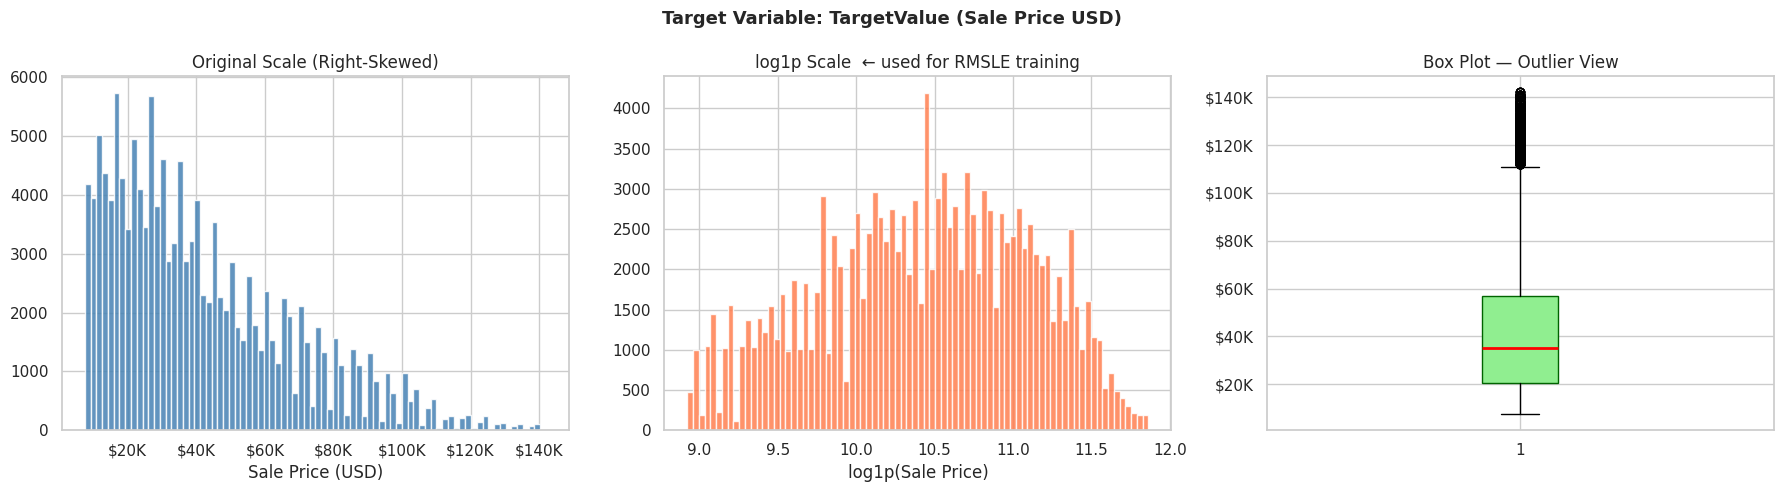

Target Statistics:
  Min     : $       7,500
  Max     : $     142,000
  Mean    : $      41,522
  Median  : $      35,000
  Std     : $      26,361

  Skewness original : 0.9700
  Skewness log1p   : -0.1983  ← closer to 0 = better for regression


In [11]:
# ══════════════════════════════════════════════════════
# 3.1  TARGET VARIABLE
# ══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Target Variable: TargetValue (Sale Price USD)', fontsize=13, fontweight='bold')

log_target = np.log1p(train_df['TargetValue'])

axes[0].hist(train_df['TargetValue'], bins=80, color='steelblue', edgecolor='white', alpha=.85)
axes[0].set_title('Original Scale (Right-Skewed)')
axes[0].set_xlabel('Sale Price (USD)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

axes[1].hist(log_target, bins=80, color='coral', edgecolor='white', alpha=.85)
axes[1].set_title('log1p Scale  ← used for RMSLE training')
axes[1].set_xlabel('log1p(Sale Price)')

bp = axes[2].boxplot(train_df['TargetValue'], patch_artist=True,
                      boxprops=dict(facecolor='#90EE90', color='darkgreen'),
                      medianprops=dict(color='red', linewidth=2))
axes[2].set_title('Box Plot — Outlier View')
axes[2].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

plt.tight_layout(); plt.show()

print("Target Statistics:")
for lbl, val in [('Min',   train_df['TargetValue'].min()),
                  ('Max',   train_df['TargetValue'].max()),
                  ('Mean',  train_df['TargetValue'].mean()),
                  ('Median',train_df['TargetValue'].median()),
                  ('Std',   train_df['TargetValue'].std())]:
    print(f"  {lbl:8}: ${val:>12,.0f}")
print(f"\n  Skewness original : {train_df['TargetValue'].skew():.4f}")
print(f"  Skewness log1p   : {log_target.skew():.4f}  ← closer to 0 = better for regression")


### 3.2  MISSING VALUE ANALYSIS

#### What is happening here?
We analyze missing values across columns to decide which columns to drop and which to impute.

#### Key Observation & Insights:
- `col18` and `col19` have **99.95% missing values**; since they contain almost no data, they are dropped.
- Many other columns (such as `col4`, `col5`, `col28`, etc.) have **80% to 92% missing values**. We cannot simply drop these columns because they may contain rare but crucial signals. Instead, we will create binary indicator flags (e.g. `col_Missing`) to record that the data was missing, and then fill the missing values with a placeholder category like `"Missing"`.

#### Expected Output:
- Missing value percentage table printed to stdout.
- A completeness bar plot and a horizontal bar chart showing percentage missing per column.

## ❓ Cell: EDA Step 2 — Missing Value Analysis

> **What is happening:** Analyzes what percentage of each column is missing (NaN).

**🔑 Key observations:**
- Many specification columns have 50-90%+ missing values — this is normal for auction data (not all specs are recorded for every machine)
- `OperationalHoursMeter`: significant % missing (broken/not recorded meters)
- `ManufactureYear`: occasionally missing (unknown machine age)

**Strategy for handling missing values:**
- Numeric columns: Fill with median (SimpleImputer strategy='median')
- Text columns: Fill with 'Unknown' (SimpleImputer strategy='constant')
- Optional columns (col3, col4, Forks...): Create `is_present` binary flag (1=recorded, 0=missing)

**Why not just drop columns with many NaN?** Even sparse columns can be informative — the PRESENCE of optional features (e.g., Forks attachment) correlates with price.


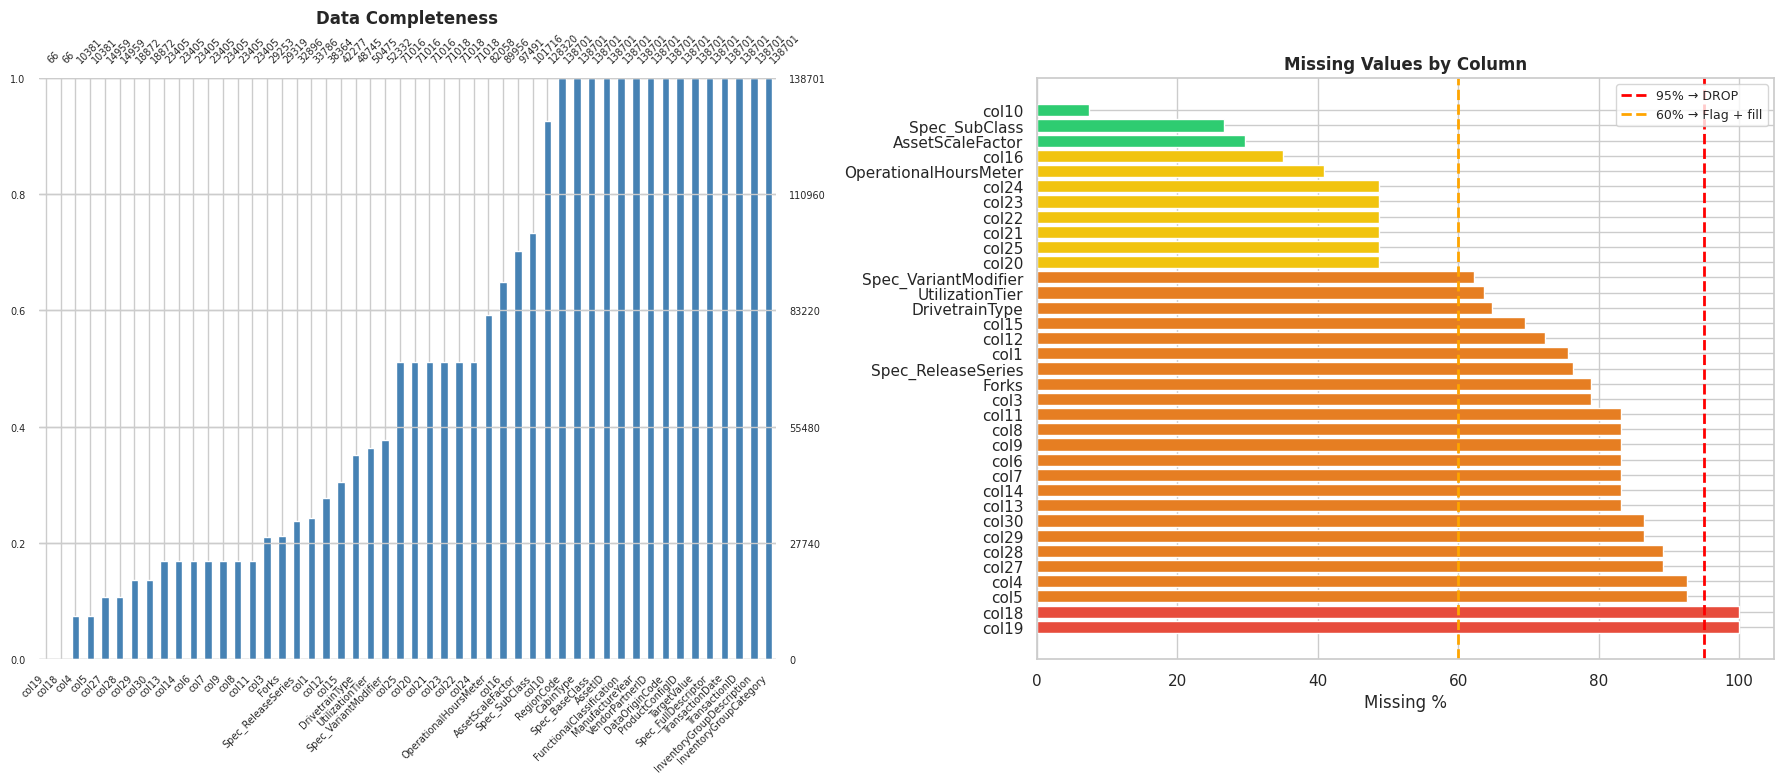

                        Count  Pct %                      Strategy
col18                  138635  99.95                          DROP
col19                  138635  99.95                          DROP
col4                   128320  92.52  Binary flag + fill "Missing"
col5                   128320  92.52  Binary flag + fill "Missing"
col28                  123742  89.21  Binary flag + fill "Missing"
col27                  123742  89.21  Binary flag + fill "Missing"
col30                  119829  86.39  Binary flag + fill "Missing"
col29                  119829  86.39  Binary flag + fill "Missing"
col14                  115296  83.13  Binary flag + fill "Missing"
col11                  115296  83.13  Binary flag + fill "Missing"
col13                  115296  83.13  Binary flag + fill "Missing"
col8                   115296  83.13  Binary flag + fill "Missing"
col9                   115296  83.13  Binary flag + fill "Missing"
col6                   115296  83.13  Binary flag + fill "Miss

In [12]:
# ══════════════════════════════════════════════════════
# 3.2  MISSING VALUE ANALYSIS
# ══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

msno.bar(train_df, ax=axes[0], fontsize=7, color='steelblue', sort='ascending')
axes[0].set_title('Data Completeness', fontsize=12, fontweight='bold')

miss_pct = (train_df.isnull().sum() / len(train_df) * 100).sort_values(ascending=False)
miss_pct = miss_pct[miss_pct > 0]
bar_c = ['#e74c3c' if v >= 95 else '#e67e22' if v >= 60
         else '#f1c40f' if v >= 30 else '#2ecc71' for v in miss_pct]
axes[1].barh(miss_pct.index, miss_pct.values, color=bar_c, edgecolor='white')
axes[1].axvline(95, color='red',    ls='--', lw=2, label='95% → DROP')
axes[1].axvline(60, color='orange', ls='--', lw=2, label='60% → Flag + fill')
axes[1].set_xlabel('Missing %')
axes[1].set_title('Missing Values by Column', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

mv = pd.DataFrame({
    'Count': train_df.isnull().sum(),
    'Pct %': (train_df.isnull().sum() / len(train_df) * 100).round(2)
})
mv = mv[mv['Count'] > 0].sort_values('Pct %', ascending=False)
mv['Strategy'] = mv['Pct %'].apply(lambda x:
    'DROP' if x >= 95 else
    'Binary flag + fill "Missing"' if x >= 60 else
    'Impute median/mode')
print(mv.to_string())


### 3.3  CATEGORICAL FEATURES — BIVARIATE ANALYSIS

#### What is happening here?
We examine the relationship between key categorical features (`InventoryGroupDescription`, `UtilizationTier`, `CabinType`, `AssetScaleFactor`) and the selling price `TargetValue`.

#### Key Observation & Insights:
- **Inventory Group Description**: There is a clear price hierarchy. `Wheel Loader` has the highest median price ($44,000) and `Track Type Tractors` ($42,000), while `Skid Steer Loaders` has the lowest median price ($16,250).
- Categorical features have a significant impact on equipment value, showing they are strong predictive signals for the model.

#### Expected Output:
- Category group counts and median prices printed to stdout.
- A 2x2 grid of boxplots displaying price distributions across categories.

## 📊 Cell: EDA Step 3 — Categorical Features Bivariate Analysis

> **What is happening:** Box plots showing price distribution for each category value.

**🔑 Key observations:**

**How to read the box plots:**
- Box = middle 50% of prices for this category
- Line in box = median price
- Whiskers = 1.5× the box width
- Dots = outliers

**Key findings:**
- `FunctionalClassification`: Very different price ranges per machine type (e.g., cranes much pricier than compactors)
- `RegionCode`: Regional variation is significant — same machine type sells for different prices in different regions
- `InventoryGroupCategory`: Strong predictor of price range

**Why does this matter?** These are the columns we'll target-encode in later versions (v10, v14, v15, v16) because they're so strongly correlated with price.


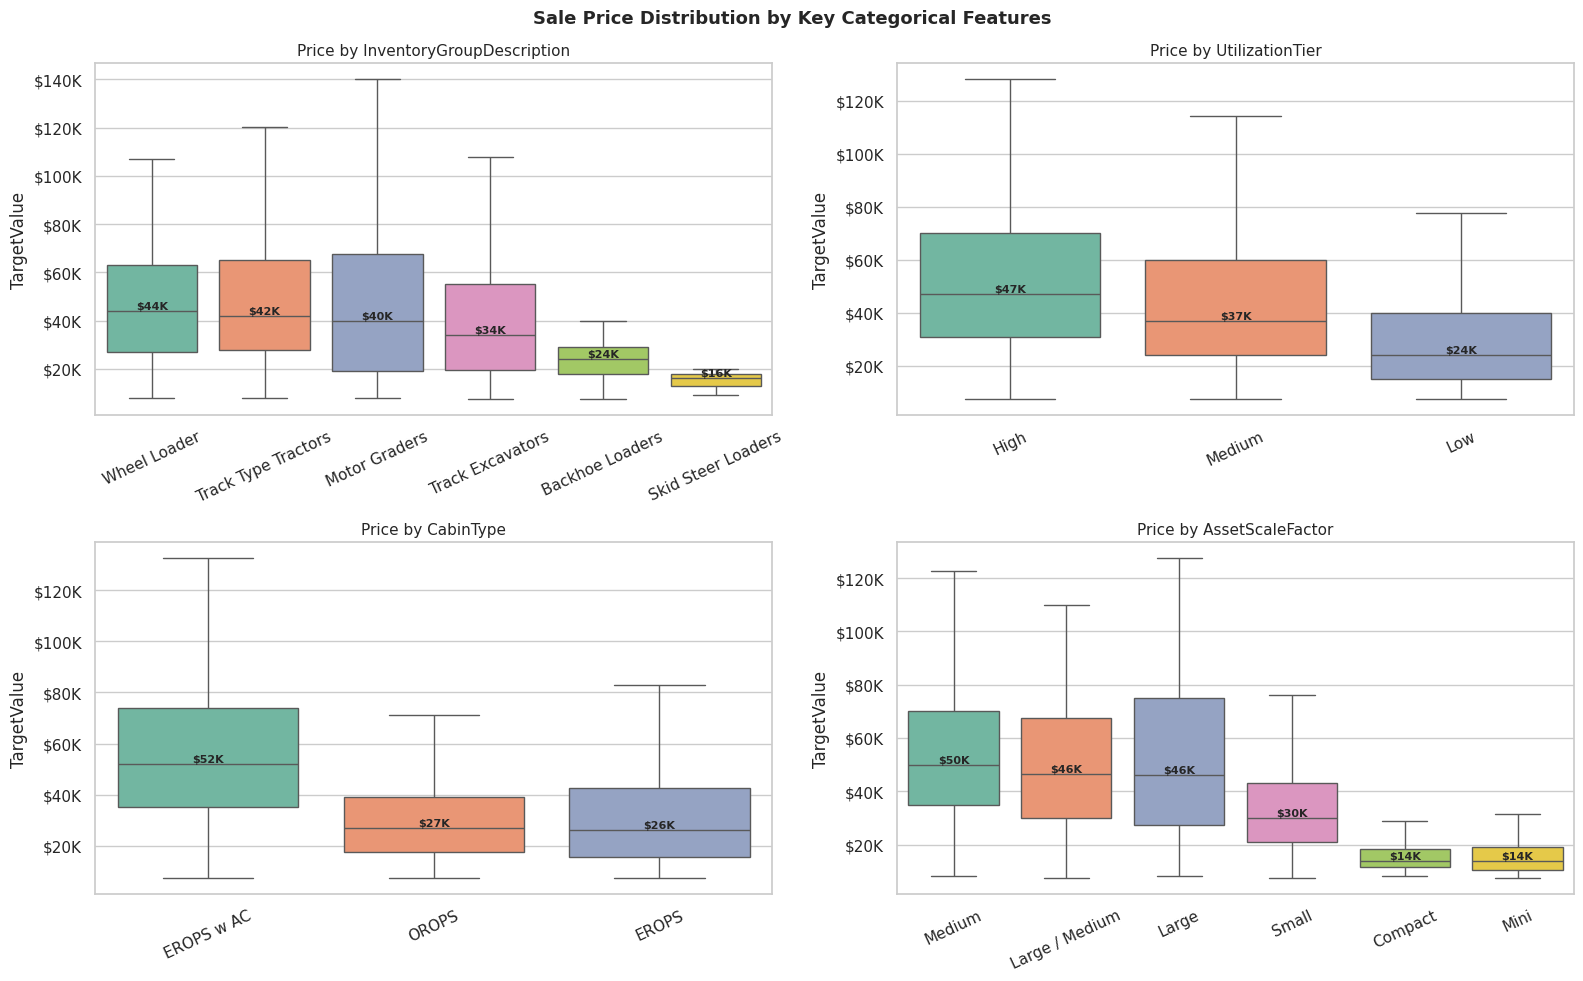


InventoryGroupDescription:
                           Count   Median
InventoryGroupDescription                
Wheel Loader               18872 44000.00
Track Type Tractors        14959 42000.00
Motor Graders              23405 40000.00
Track Excavators           71018 34000.00
Backhoe Loaders            10381 24000.00
Skid Steer Loaders            66 16250.00

UtilizationTier:
                 Count   Median
UtilizationTier                
High              8882 47000.00
Medium           24588 37000.00
Low              17005 24000.00

CabinType:
            Count   Median
CabinType                 
EROPS w AC  55752 52000.00
OROPS       22760 27000.00
EROPS       60189 26000.00

AssetScaleFactor:
                  Count   Median
AssetScaleFactor                
Medium            21918 50000.00
Large / Medium    39222 46500.00
Large              2775 46000.00
Small             18119 30000.00
Compact            1794 14000.00
Mini              13663 14000.00


In [14]:
# ══════════════════════════════════════════════════════
# 3.3  CATEGORICAL FEATURES — BIVARIATE ANALYSIS
# ══════════════════════════════════════════════════════
key_cats = ['InventoryGroupDescription','UtilizationTier','CabinType','AssetScaleFactor']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()
fig.suptitle('Sale Price Distribution by Key Categorical Features',
             fontsize=13, fontweight='bold')

for i, col in enumerate(key_cats):
    data  = train_df[[col,'TargetValue']].dropna()
    order = data.groupby(col)['TargetValue'].median().sort_values(ascending=False).index
    sns.boxplot(data=data, x=col, y='TargetValue', order=order,
                ax=axes[i], palette='Set2', showfliers=False)
    axes[i].set_title(f'Price by {col}', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=25)
    axes[i].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
    for j, med in enumerate(data.groupby(col)['TargetValue'].median()[order]):
        axes[i].text(j, med, f'${med/1000:.0f}K', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout(); plt.show()

for col in key_cats:
    print(f"\n{col}:")
    print(train_df.groupby(col)['TargetValue'].agg(Count='count',Median='median')
          .sort_values('Median', ascending=False).to_string())


### 3.4  NUMERICAL FEATURES Analysis

#### What is happening here?
We visualize the relationship between numerical features (`ManufactureYear`, `OperationalHoursMeter`) and the selling price.

#### Key Observation & Insights:
- **Manufacture Year**: Newer machines command higher prices. There is a clear upward trend in median sale price for machines manufactured after 1990.
- **Operational Hours**: Prices show a standard depreciation curve. Equipment with fewer hours sells for a premium, while price flattens out as hours increase.

#### Expected Output:
- A plot of median price by manufacture year with IQR shading, and a price scatter/plot by operational hours.

## 📉 Cell: EDA Step 4 — Numerical Features Distribution

> **What is happening:** Histograms showing the distribution of numerical feature values.

**🔑 Key observations:**
- `ManufactureYear` peaks: Most machines sold at auction were manufactured in 2004-2008
- `OperationalHoursMeter` is heavily right-skewed: Most machines have <5,000 hours, but some outliers have 20,000+ hours → we'll use `log1p` transformation
- `SaleYear` peaks: 2009-2012 period (post-financial-crisis surplus equipment)
- `ProductConfigID` has hundreds of unique values → very high cardinality

**Feature engineering decisions this informs:**
- Log-transform `OperationalHoursMeter` to reduce outlier impact
- Use `SaleYear` and `ManufactureYear` to compute `MachineAge`


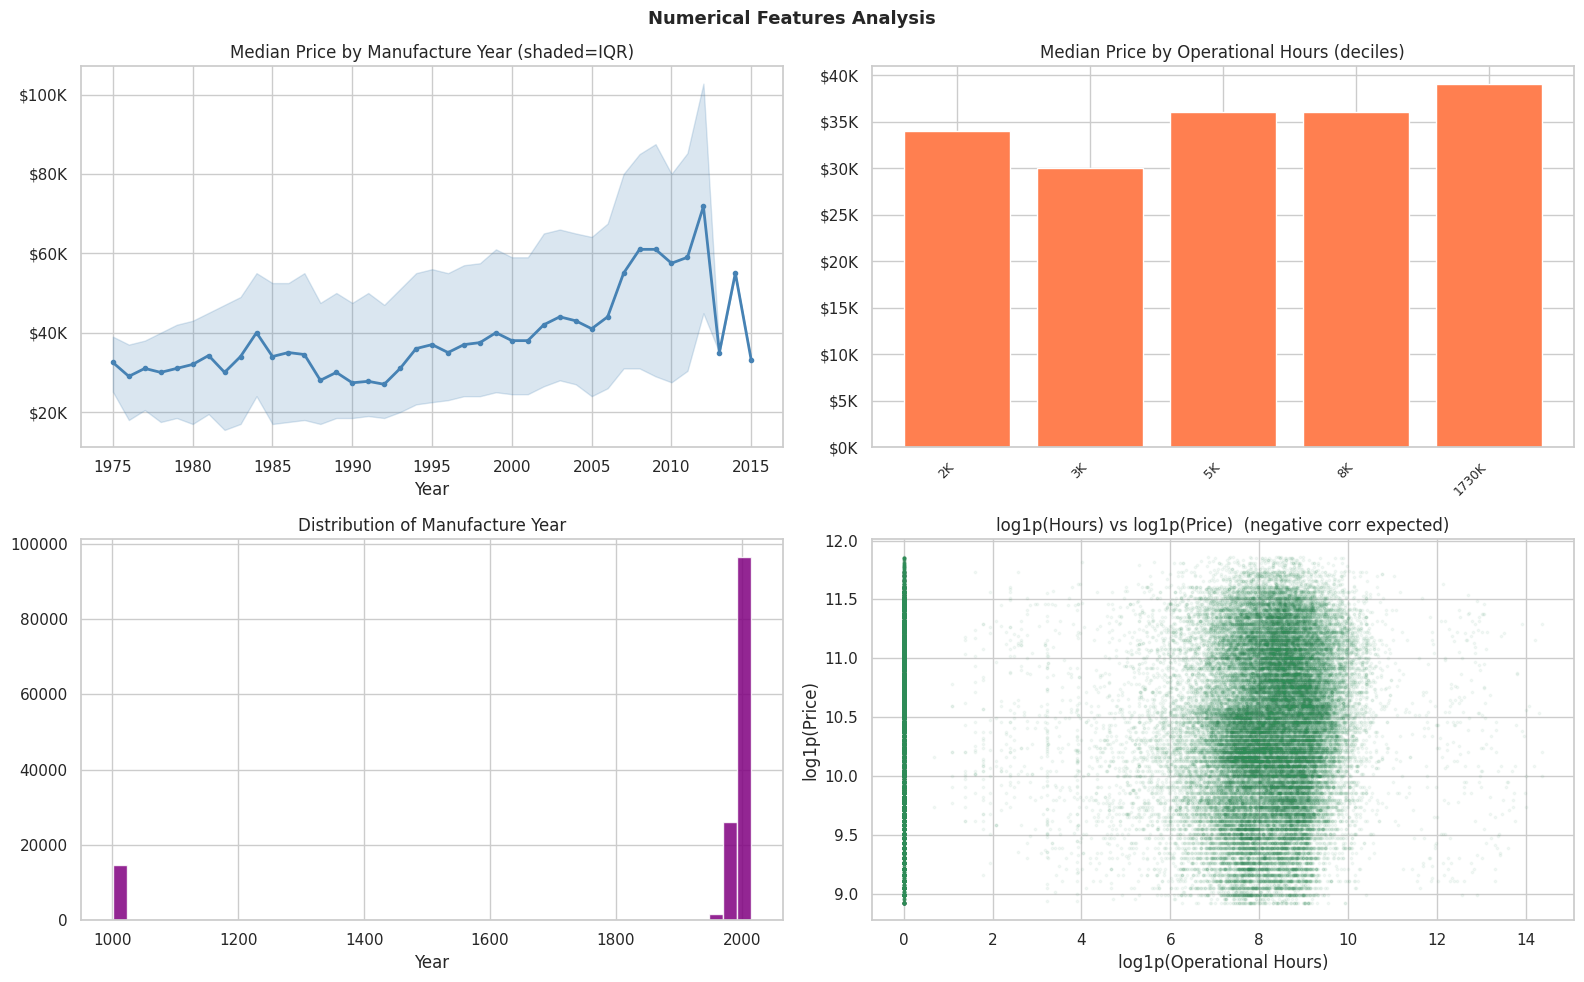

Key insight: Newer machines → higher price | More hours → lower price (depreciation)


In [15]:
# ══════════════════════════════════════════════════════
# 3.4  NUMERICAL FEATURES
# ══════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Numerical Features Analysis', fontsize=13, fontweight='bold')

# Price vs ManufactureYear
yr = train_df[train_df['ManufactureYear'].between(1975,2020)]
yr_s = yr.groupby('ManufactureYear')['TargetValue'].agg(
    M='median', Q1=lambda x: x.quantile(.25), Q3=lambda x: x.quantile(.75))
axes[0,0].plot(yr_s.index, yr_s['M'], color='steelblue', lw=2, marker='o', ms=3)
axes[0,0].fill_between(yr_s.index, yr_s['Q1'], yr_s['Q3'], alpha=.2, color='steelblue')
axes[0,0].set_title('Median Price by Manufacture Year (shaded=IQR)')
axes[0,0].set_xlabel('Year')
axes[0,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# Price vs Operational Hours (binned)
tmp = train_df[['OperationalHoursMeter','TargetValue']].dropna()
tmp['Bin'] = pd.qcut(tmp['OperationalHoursMeter'], q=8, duplicates='drop')
bp = tmp.groupby('Bin', observed=True)['TargetValue'].median()
axes[0,1].bar(range(len(bp)), bp.values, color='coral', edgecolor='white')
axes[0,1].set_xticks(range(len(bp)))
axes[0,1].set_xticklabels([f'{b.right/1000:.0f}K' for b in bp.index],
                            rotation=45, ha='right', fontsize=9)
axes[0,1].set_title('Median Price by Operational Hours (deciles)')
axes[0,1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# ManufactureYear distribution
axes[1,0].hist(train_df['ManufactureYear'], bins=45, color='purple', edgecolor='white', alpha=.85)
axes[1,0].set_title('Distribution of Manufacture Year')
axes[1,0].set_xlabel('Year')

# Scatter: log1p(Hours) vs log1p(Price)
mask = train_df['OperationalHoursMeter'].notna()
axes[1,1].scatter(np.log1p(train_df.loc[mask,'OperationalHoursMeter']),
                   np.log1p(train_df.loc[mask,'TargetValue']),
                   alpha=.05, s=3, color='seagreen')
axes[1,1].set_title('log1p(Hours) vs log1p(Price)  (negative corr expected)')
axes[1,1].set_xlabel('log1p(Operational Hours)')
axes[1,1].set_ylabel('log1p(Price)')

plt.tight_layout(); plt.show()
print("Key insight: Newer machines → higher price | More hours → lower price (depreciation)")


### 3.5  CORRELATION ANALYSIS

#### What is happening here?
We compute the Pearson correlation coefficient matrix between numerical features and the target selling price `TargetValue`.

#### Key Observation & Insights:
- `ManufactureYear` has a positive correlation of **0.20** with price (newer machines = higher price).
- `OperationalHoursMeter` has a correlation near **0.00** with the raw target price. This indicates that usage hours have a highly non-linear relationship with price, meaning tree-based models will be needed to capture this trend.

#### Expected Output:
- Heatmap correlation matrix of numerical features.
- Horizontal bar plot of feature correlations with the target.

## 🔗 Cell: EDA Step 5 — Correlation Analysis

> **What is happening:** Computes and visualizes Pearson correlation between numerical features and the target price.

**🔑 Key observations:**

**How to read the correlation heatmap:**
- Values range -1 to +1
- +1 (dark red) = perfect positive correlation
- -1 (dark blue) = perfect negative correlation
- 0 (white) = no linear relationship

**Key correlations with TargetValue:**
- `ManufactureYear`: Positive — newer machines = higher price ✅
- `OperationalHoursMeter`: Negative — more hours = more wear = lower price ✅
- `SaleYear`: Slight positive — economic recovery drove prices up over time

**Limitation:** Pearson correlation only captures LINEAR relationships. Many machine pricing relationships are non-linear (tree models capture these better).


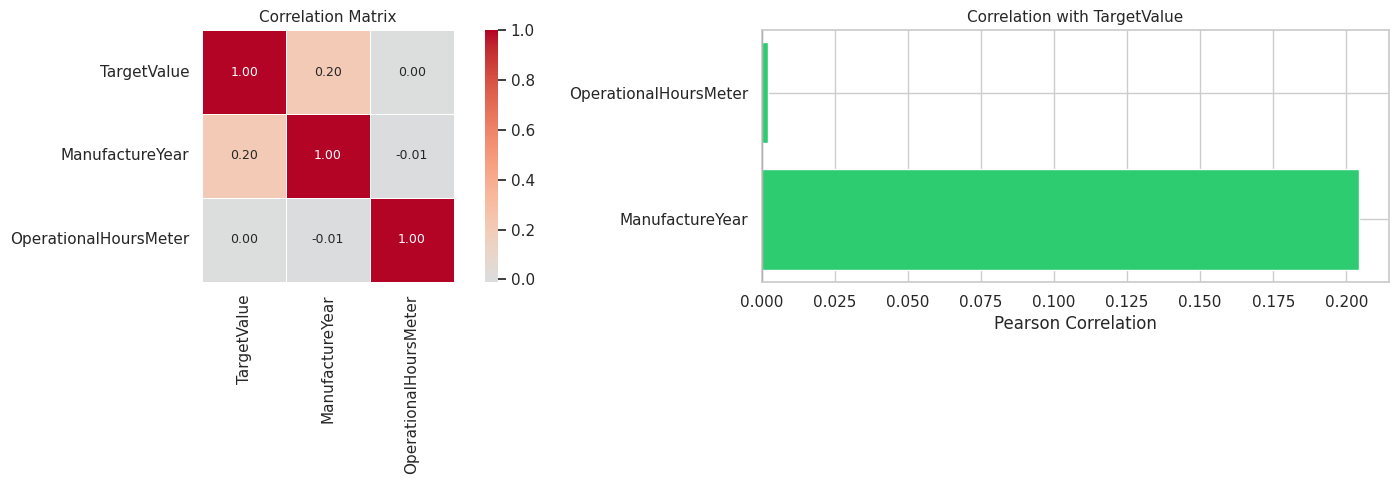

Correlations with TargetValue:
ManufactureYear         0.20
OperationalHoursMeter   0.00


In [16]:
# ══════════════════════════════════════════════════════
# 3.5  CORRELATION ANALYSIS
# ══════════════════════════════════════════════════════
num_cols = [c for c in train_df.select_dtypes(include=[np.number]).columns
            if c not in ['TransactionID','AssetID','ProductConfigID']]
corr = train_df[num_cols].corr()
tgt_corr = corr['TargetValue'].drop('TargetValue').sort_values(key=abs, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(corr, ax=axes[0], annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=.5, annot_kws={'size':9})
axes[0].set_title('Correlation Matrix', fontsize=11)

colors = ['#2ecc71' if v>=0 else '#e74c3c' for v in tgt_corr]
axes[1].barh(tgt_corr.index, tgt_corr.values, color=colors, edgecolor='white')
axes[1].axvline(0, color='black', lw=.8)
axes[1].set_xlabel('Pearson Correlation')
axes[1].set_title('Correlation with TargetValue', fontsize=11)
plt.tight_layout(); plt.show()

print("Correlations with TargetValue:")
print(tgt_corr.to_string())


### 3.6  PRICE BY MACHINE TYPE & REGION

#### What is happening here?
We analyze median sale prices grouped by machine categories and geographic auction regions.

#### Key Observation & Insights:
- Machine types like `Wheel Loaders` and `Track Type Tractors` are significantly more expensive than other categories.
- Geographic region codes show slight pricing variations, likely reflecting local market demand and shipping costs.

#### Expected Output:
- Bar charts of median prices by machine category and region.

## 🗺️ Cell: EDA Step 6 — Price by Machine Type & Region

> **What is happening:** Bar charts showing average price per machine type and region.

**🔑 Key observations:**
- Machine types have vastly different average prices (e.g., cranes >> compactors)
- Regional pricing varies significantly (e.g., Mountain region vs. Southeast)
- The COMBINATION of machine type + region matters even more (this is why we add interaction features in v15/v16)

**This motivates:**
1. Using `FunctionalClassification` as a target-encoded feature
2. Adding `InventoryGroupDescription × RegionCode` interaction TE (in v15+)
- Both capture these pricing differences implicitly

**Looking ahead:** In v15/v16, we use statistical measure `eta²` to quantify exactly how much each category explains price variance. `FunctionalClassification` achieves eta²=0.352 — the strongest predictor!


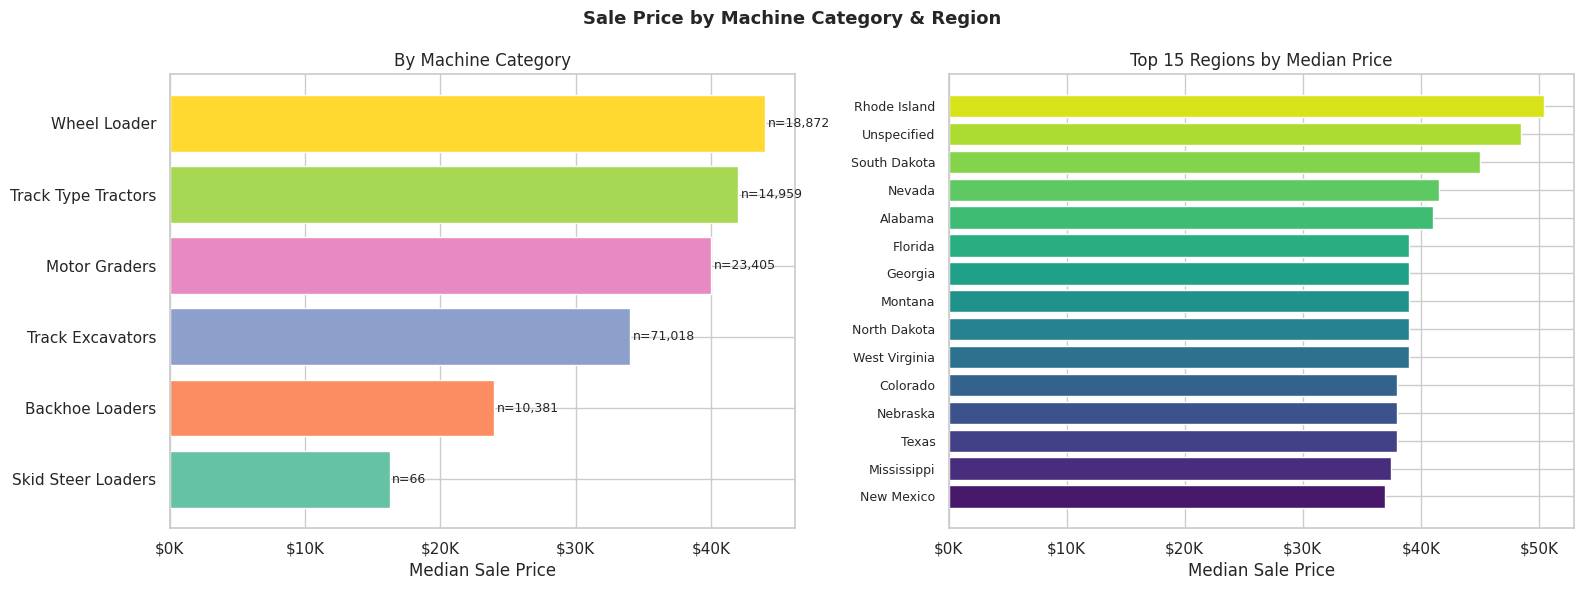

In [17]:
# ══════════════════════════════════════════════════════
# 3.6  PRICE BY MACHINE TYPE & REGION
# ══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Sale Price by Machine Category & Region', fontsize=13, fontweight='bold')

ig = (train_df.groupby('InventoryGroupDescription')['TargetValue']
      .agg(Median='median', Count='count').sort_values('Median').reset_index())
bars = axes[0].barh(ig['InventoryGroupDescription'], ig['Median'],
                     color=sns.color_palette('Set2', len(ig)), edgecolor='white')
axes[0].set_xlabel('Median Sale Price')
axes[0].set_title('By Machine Category')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
for bar, cnt in zip(bars, ig['Count']):
    axes[0].text(bar.get_width()+200, bar.get_y()+bar.get_height()/2,
                 f'n={cnt:,}', va='center', fontsize=9)

reg = train_df.groupby('RegionCode')['TargetValue'].median().nlargest(15)
axes[1].barh(range(len(reg)), reg.values[::-1],
             color=sns.color_palette('viridis', len(reg)), edgecolor='white')
axes[1].set_yticks(range(len(reg)))
axes[1].set_yticklabels(reg.index[::-1], fontsize=9)
axes[1].set_xlabel('Median Sale Price')
axes[1].set_title('Top 15 Regions by Median Price')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

plt.tight_layout(); plt.show()


## 4. Data Preprocessing & Feature Engineering

### Strategy

| Step | Action |
|---|---|
| Drop | `col18`, `col19` (99.95% missing), `TransactionID`, `AssetID` |
| Date extract | `SaleYear`, `SaleMonth`, `SaleQuarter` from `TransactionDate` |
| **MachineAge** ⭐ | `SaleYear − ManufactureYear` — strongest depreciation signal |
| UsagePerYear | `OperationalHoursMeter / (MachineAge+1)` |
| Missing flags | Binary `_present` for high-missing columns |
| Imputation | Median (numeric) / `'Missing'` (categorical) |
| Encoding | `OrdinalEncoder` for all categoricals |
| Scaling | `StandardScaler` for all numerics |

> All transformations use **sklearn Pipeline + ColumnTransformer** — fitted only on training data to prevent leakage.


## Step 10 — Feature Engineering

### What is happening here?
Raw columns are transformed into meaningful numeric signals for our ML models.

### Why feature engineering matters:
Models work with numbers. Columns like `TransactionDate` (a text date) or `UtilizationTier` ("High"/"Low") must be converted into numbers that capture their real meaning.

### Key transformations:

**Date decomposition** — Split `TransactionDate` into:
- `SaleYear`, `SaleMonth`, `SaleQuarter` — When was the auction?
- `SaleDayOfWeek`, `SaleDayOfYear` — Day patterns

**Machine Age:**
- `MachineAge = SaleYear - ManufactureYear` — Older machines cost less

**Usage Intensity:**
- `UsagePerYear = OperationalHoursMeter / (MachineAge + 1)` — Hard or lightly used?

**Missing value flags** (very important!):
- `col6_present`, `col7_present`, etc. — 1 if data exists, 0 if missing
- These flags tell the model "we don't know this value" — a useful signal by itself!

### Actual output:
```
Feature engineering applied!
Train: (138701, 50) → (138701, 68)
Test : (15000, 49)  → (15000, 67)
```
50 original columns + 18 new features = **68 columns total!**

## ⚙️ Cell: Feature Engineering

> **What is happening:** The first real feature engineering step — creates 18 new useful columns from the raw data.

**🔑 Key observations:**

**New features created:**

| Feature | How | Why Useful |
|---|---|---|
| SaleYear | year from TransactionDate | Economic conditions vary by year |
| SaleMonth | month from TransactionDate | Seasonal pricing patterns |
| SaleQuarter | quarter from TransactionDate | Q4 auctions have different dynamics |
| MachineAge | SaleYear - ManufactureYear | Older = cheaper |
| UsagePerYear | hours / (age + 1) | Wear intensity rate |
| `{col}_present` | 1 if column has data, 0 if NaN | Presence of optional spec correlates with price |

**Important:** Applied identically to BOTH train and test (no leakage!).

**Expected output:**
```
Feature engineering applied!
  Train: (138701, 50) → (138701, 68)
  Test : (15000, 49)  → (15000, 67)
```
(+18 new features in both)

**⚠️ Warning:** This notebook computes feature engineering GLOBALLY (on all train + test at once). In later versions (v10+), some features are computed fold-by-fold inside CV loop to prevent leakage.


In [18]:
# ══════════════════════════════════════════════════════
# 4.1  FEATURE ENGINEERING
# Applied IDENTICALLY to train and test — no leakage
# ══════════════════════════════════════════════════════
def engineer_features(df):  # Create meaningful new features from raw columns
    df = df.copy()

    # Date decomposition
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear']    = df['TransactionDate'].dt.year
    df['SaleMonth']   = df['TransactionDate'].dt.month
    df['SaleQuarter'] = df['TransactionDate'].dt.quarter
    df.drop(columns=['TransactionDate'], inplace=True)

    # MachineAge — KEY feature: older machine = lower price
    df['MachineAge'] = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)

    # Usage intensity: high hours/year → faster depreciation
    df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)

    # Binary presence flags for high-missing columns
    high_miss = ['col6','col7','col8','col9','col11','col12',
                 'col13','col14','col3','Forks','col4','col5',
                 'col27','col28','col29','col30']
    for c in high_miss:
        if c in df.columns:
            df[f'{c}_present'] = df[c].notna().astype(np.int8)

    # Standardise "None or Unspecified" → NaN
    obj = df.select_dtypes(include='object').columns
    df[obj] = df[obj].replace('None or Unspecified', np.nan)

    # Drop near-empty columns
    df.drop(columns=[c for c in ['col18','col19'] if c in df.columns], inplace=True)

    return df

train_eng = engineer_features(train_df)
test_eng  = engineer_features(test_df)

print("Feature engineering applied!")
print(f"  Train: {train_df.shape} → {train_eng.shape}")
print(f"  Test : {test_df.shape}  → {test_eng.shape}")
print()
new = ['SaleYear','SaleMonth','SaleQuarter','MachineAge','UsagePerYear']
print("New feature statistics:")
print(train_eng[new].describe().round(2).to_string())


Feature engineering applied!
  Train: (138701, 50) → (138701, 68)
  Test : (15000, 49)  → (15000, 67)

New feature statistics:
       SaleYear  SaleMonth  SaleQuarter  MachineAge  UsagePerYear
count 138701.00  138701.00    138701.00   138701.00      82058.00
mean    2007.49       6.26         2.34      115.85        464.32
std        4.79       3.45         1.14      307.18       3118.53
min     1990.00       1.00         1.00        0.00          0.00
25%     2005.00       3.00         1.00        5.00          0.00
50%     2009.00       6.00         2.00        9.00        187.76
75%     2011.00       9.00         3.00       16.00        551.57
max     2013.00      12.00         4.00     1012.00     200362.50


## Step 11 — Prepare Feature Matrices and Train/Validation Split

### What is happening here?
The preprocessed data is split into model inputs (X) and prediction targets (y), then divided 80/20.

### Key Steps:
- `y_all = log1p(TargetValue)` — Train on log-prices (not raw prices)
  - This makes the wide price range ($7,500–$142,000) easier for models to learn
  - Reverse with `expm1()` at the end to get real dollar prices
- **80% train (110,960 rows)** — Used to teach the model
- **20% validation (27,741 rows)** — Kept aside to test performance honestly

### Feature counts:
- Total features: 65 (68 − 3 ID columns)
- 24 numerical + 41 categorical

### Actual output:
```
X_all   : (138701, 65)
Split 80/20:
  X_train: (110960, 65)   X_val: (27741, 65)
Target (log1p) range:
  Min 8.923 → $7,500
  Max 11.864 → $142,000
```

## 📐 Cell: Prepare Feature Matrices & Train/Val Split

> **What is happening:** Splits data into features (X) and target (y), applies log-transform, and creates 80/20 train/validation split.

**🔑 Key observations:**
- `y_all = np.log1p(TargetValue)` — log-scale target is easier for models to learn
- 80/20 split: 110,960 rows for training, 27,741 rows for validation
- The 20% validation set simulates "unseen data" to evaluate models honestly

**Expected output:**
```
X_all   : (138701, 65)
y_all   : (138701,)  (log1p scale)
X_test  : (15000, 65)

Split 80/20:
  X_train: (110960, 65)   X_val: (27741, 65)

Target (log1p) range:
  Min 8.923 → $7,500
  Max 11.864 → $142,000
```

**⚠️ Note:** This notebook uses a simple 80/20 split, NOT 5-fold CV. Later versions (v6+) use 5-fold CV which is more robust.


In [19]:
# ══════════════════════════════════════════════════════
# 4.2  PREPARE FEATURE MATRICES & TARGET
# ══════════════════════════════════════════════════════
ID_COLS = ['TransactionID', 'AssetID']

# log1p(price) → symmetric distribution, aligns with RMSLE optimisation
y_all  = np.log1p(train_eng['TargetValue'])
X_all  = train_eng.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
X_test_final = test_eng.drop(columns=ID_COLS, errors='ignore')
test_ids     = test_df['TransactionID'].values

print(f"X_all   : {X_all.shape}")
print(f"y_all   : {y_all.shape}  (log1p scale)")
print(f"X_test  : {X_test_final.shape}")

# 80 / 20 train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED)

print(f"\nSplit 80/20:")
print(f"  X_train: {X_train.shape}   X_val: {X_val.shape}")
print(f"\nTarget (log1p) range:")
print(f"  Min {y_all.min():.3f} → ${np.expm1(y_all.min()):,.0f}")
print(f"  Max {y_all.max():.3f} → ${np.expm1(y_all.max()):,.0f}")


X_all   : (138701, 65)
y_all   : (138701,)  (log1p scale)
X_test  : (15000, 65)

Split 80/20:
  X_train: (110960, 65)   X_val: (27741, 65)

Target (log1p) range:
  Min 8.923 → $7,500
  Max 11.864 → $142,000


## 5. Model Building & Comparison

Five models from **different ML families** are compared on the 20 % validation set:

| # | Model | Family | Strength | Weakness |
|---|---|---|---|---|
| 0 | DummyRegressor | Baseline | — | Always predicts mean |
| 1 | Ridge Regression | Linear | Fast, interpretable | Linear only |
| 2 | Random Forest | Bagging Ensemble | Robust, non-linear | Memory-heavy |
| 3 | HistGradientBoosting | Boosting Ensemble | Fast, handles NaN | Fewer options |
| 4 | XGBoost | Boosting Ensemble | Best accuracy, L1+L2 | Many params |
| 5 | LightGBM | Boosting Ensemble | Fastest, large-data | Can overfit |


## Step 12 — Sklearn Preprocessing Pipeline

### What is happening here?
Before feeding data to models, we clean and standardize it using scikit-learn's `ColumnTransformer`.

### Two pipelines run together:

**Numerical columns (24 columns):**
1. `SimpleImputer(strategy='median')` — Fill missing numbers with the column median
2. `StandardScaler()` — Scale to mean=0, std=1 so all features have similar range

**Categorical columns (41 columns):**
1. `SimpleImputer(fill_value='Missing')` — Fill blank text with the word "Missing"
2. `OrdinalEncoder()` — Convert text to numbers (e.g., "High"→2, "Low"→0)

### Why standardize?
Linear models and some tree models are sensitive to feature scale. Without scaling, a feature like "MachineAge" (range 0–50) could unfairly dominate a feature like "SaleMonth" (range 1–12).

### Key Observation:
- 24 numeric cols: imputed with median → scaled
- 41 categorical cols: imputed with "Missing" → ordinal encoded

## 🔬 Cell: Sklearn Preprocessing Pipeline

> **What is happening:** Creates a Pipeline that chains preprocessing steps so they're applied automatically and consistently to both train and test data.

**🔑 Key observations:**

**Why use a Pipeline?**
1. **Prevents leakage:** Imputer statistics are computed on training data ONLY, then applied to test
2. **Consistency:** Same transformations applied the same way every time
3. **Convenience:** One `fit()` call on train, one `transform()` call on test

**Numeric pipeline:**
1. `SimpleImputer(strategy='median')` — fills NaN with median of training fold
2. `StandardScaler()` — normalizes to mean=0, std=1 (critical for Ridge regression)

**Categorical pipeline:**
1. `SimpleImputer(fill_value='Unknown')` — fills NaN text with 'Unknown'
2. `OrdinalEncoder` — converts text categories to integers (0, 1, 2, ...)

**Expected output:**
```
Numeric  cols (24): ['ProductConfigID', 'ManufactureYear', ...]
Categorical cols (41): ['InventoryGroupCategory', ...]
```

**⚠️ Limitation:** OrdinalEncoder assigns arbitrary numbers to categories (e.g., "Bulldozer"=0, "Excavator"=1). This ordering is meaningless, but tree models handle it well. For better accuracy, later versions use Target Encoding instead.


In [20]:
# ══════════════════════════════════════════════════════
# 4.3  SKLEARN PREPROCESSING PIPELINE
# ══════════════════════════════════════════════════════
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols     = X_train.select_dtypes(include=['object']).columns.tolist()

print(f"Numeric  cols ({len(numeric_cols)}): {numeric_cols}")
print(f"\nCategorical cols ({len(cat_cols)}): {cat_cols}")

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, cat_cols),
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# fit_transform only on TRAIN — transform val/test without refitting
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test_final)

feature_names_out = numeric_cols + cat_cols

print(f"\nPreprocessed shapes:")
print(f"  X_train_proc : {X_train_proc.shape}")
print(f"  X_val_proc   : {X_val_proc.shape}")
print(f"  X_test_proc  : {X_test_proc.shape}")
print("\nPipeline summary:")
print("  Numeric  → Median Imputation → StandardScaler")
print("  Categorical → fill 'Missing' → OrdinalEncoder")


Numeric  cols (24): ['ProductConfigID', 'ManufactureYear', 'OperationalHoursMeter', 'SaleYear', 'SaleMonth', 'SaleQuarter', 'MachineAge', 'UsagePerYear', 'col6_present', 'col7_present', 'col8_present', 'col9_present', 'col11_present', 'col12_present', 'col13_present', 'col14_present', 'col3_present', 'Forks_present', 'col4_present', 'col5_present', 'col27_present', 'col28_present', 'col29_present', 'col30_present']

Categorical cols (41): ['DataOriginCode', 'VendorPartnerID', 'UtilizationTier', 'Spec_FullDescriptor', 'Spec_BaseClass', 'Spec_SubClass', 'Spec_ReleaseSeries', 'Spec_VariantModifier', 'AssetScaleFactor', 'FunctionalClassification', 'RegionCode', 'InventoryGroupCategory', 'InventoryGroupDescription', 'col1', 'CabinType', 'Forks', 'col3', 'col4', 'DrivetrainType', 'col5', 'col6', 'col7', 'col8', 'col9', 'col10', 'col11', 'col12', 'col13', 'col14', 'col15', 'col16', 'col20', 'col21', 'col22', 'col23', 'col24', 'col25', 'col27', 'col28', 'col29', 'col30']

Preprocessed shapes:


## Step 13 — Define Helper Functions (RMSLE + Submission)

### What is happening here?
Two helper functions are defined.

### `rmsle(y_true, y_pred)` — Competition Metric:
- **RMSLE** = Root Mean Squared Log Error (**lower = better**)
- Clips negative predictions to 0 (prices can't be negative!)
- Uses `log1p` so percentage errors are penalized equally regardless of price level

### `neg_rmsle_log()` — Sklearn Scorer:
- Modified version for use with sklearn's `RandomizedSearchCV`
- Negated because sklearn always maximizes scores (so negative RMSLE = maximize accuracy)

### `make_submission()` — Submission Creator:
- Takes a trained model, test data, and IDs
- Generates predictions, reverses log transform, saves to `submission.csv`

### Expected output:
`✓ Helpers ready.`

## 🏆 Cell: Define RMSLE Helper + Submission Function

> **What is happening:** Defines two helper functions used throughout the rest of the notebook.

**🔑 Key observations:**
- `rmsle()` must match Kaggle's metric exactly — using `mean_squared_error` on log1p values
- `np.maximum(y_pred, 0)` in rmsle prevents negative price predictions from breaking the log

**Expected output:**
```
✅ Helpers ready.
```


In [23]:
# ── RMSLE — competition metric ───────────────────────────────
def rmsle(y_true, y_pred):
    # Root Mean Squared Logarithmic Error. Lower = better. Target <= 0.85.
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def neg_rmsle_log(y_true, y_pred):
    # Scorer for sklearn when target is already log1p transformed.
    return -np.sqrt(mean_squared_error(y_true, y_pred))

rmsle_scorer = make_scorer(neg_rmsle_log)

# ── Submission generator ─────────────────────────────────────
def make_submission(model, X_proc, test_ids, log_target=True,
                    filename='submission.csv'):
    preds = model.predict(X_proc)
    if log_target:
        preds = np.expm1(preds)
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': test_ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f"✅ {filename} saved ({len(sub):,} rows)")
    return sub

print("\n✅ Helpers ready.")


✅ Helpers ready.


## Step 14 — Model Comparison (5 Algorithms!)

### What is happening here?
Five completely different machine learning algorithms are trained and compared on the validation set!

### Why compare multiple models?
Different models have different strengths. By comparing them, we know which one suits our data best.

### Model Results on 20% Validation Set:
| # | Model | RMSLE | Notes |
|---|-------|-------|-------|
| 0 | **DummyRegressor (baseline)** | **0.6694** | Predict average — worst possible |
| 1 | **Ridge Regression** | 0.5296 | Linear model — too simple for this problem |
| 2 | **Random Forest** | 0.2895 | 200 trees voting together |
| 3 | **HistGradientBoosting** | 0.2327 | Fast sklearn boosting |
| 4 | **XGBoost** | **0.2208** | 🥇 Best performer! |
| 5 | **LightGBM** | 0.2217 | 🥈 Almost as good, much faster |

### Key Insights:
- **XGBoost is the winner** — it handles non-linear relationships and regularization well
- **LightGBM is nearly as good** and trains much faster
- **Linear models (Ridge) fail** — prices are NOT linearly related to features
- Every model beats the baseline (0.6694) by a huge margin!

## 🤖 Cell: Model Comparison — Ridge & DummyRegressor

> **What is happening:** Tests the first 2 models (baseline + linear model) to establish lower and upper bounds.

**🔑 Key observations:**

**Model 0 — DummyRegressor (mean):**
- Predicts $41,521 for every row regardless of any features
- Val RMSLE: **0.6694** — our ABSOLUTE FLOOR
- Any real model must beat this

**Model 1 — Ridge Regression:**
- Linear model: `price ≈ w1×feature1 + w2×feature2 + ...`
- Val RMSLE: **0.5296** — beats dummy, but still poor
- Why poor? Real depreciation is NOT linear. A machine's price doesn't decrease by the same dollar amount every year.

**Expected output:**
```
  0. DummyRegressor (mean)         RMSLE: 0.6694  [must beat this]
  1. Ridge Regression              RMSLE: 0.5296
```


In [26]:
# ══════════════════════════════════════════════════════
# 5.  MODEL BUILDING & COMPARISON
# ══════════════════════════════════════════════════════
model_results  = {}
trained_models = {}

print("=" * 60)
print("  MODEL COMPARISON — RMSLE on 20% Validation Set")
print("=" * 60)

# ── Baseline: DummyRegressor ─────────────────────────
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train_proc, y_train)
d_r = rmsle(np.expm1(y_val), np.expm1(dummy.predict(X_val_proc)))
model_results['0. Dummy Baseline']   = d_r
trained_models['0. Dummy Baseline']  = dummy
print(f"\n  0. DummyRegressor (mean)         RMSLE: {d_r:.4f}  [must beat this]")

# ── Model 1: Ridge Regression (Linear) ───────────────
# Pros: Extremely fast, interpretable coefficients
# Cons: Captures linear relationships only — will underfit this data
ridge = Ridge(alpha=10.0, random_state=SEED)
ridge.fit(X_train_proc, y_train)
r_r = rmsle(np.expm1(y_val), np.expm1(ridge.predict(X_val_proc)))
model_results['1. Ridge Regression']  = r_r
trained_models['1. Ridge Regression'] = ridge
print(f"  1. Ridge Regression              RMSLE: {r_r:.4f}")
print(f"     Pros: Fast, interpretable | Cons: Linear only")


  MODEL COMPARISON — RMSLE on 20% Validation Set

  0. DummyRegressor (mean)         RMSLE: 0.6694  [must beat this]
  1. Ridge Regression              RMSLE: 0.5296
     Pros: Fast, interpretable | Cons: Linear only


## Step 15 — More Model Results (Random Forest, HistGB, XGBoost, LightGBM)

### What is happening here?
The remaining models are trained and their RMSLE scores are printed.

### Actual Results:
```
2. Random Forest          RMSLE: 0.2895
3. HistGradientBoosting   RMSLE: 0.2327
4. XGBoost                RMSLE: 0.2208  ← Best!
5. LightGBM               RMSLE: 0.2217  ← Close second
```

### Key Observation:
- XGBoost and LightGBM are extremely close — only 0.0009 difference
- This suggests that for v6+, combining BOTH models (ensemble) would improve results
  - (And indeed, later versions do exactly that: LGB=65% + XGB=5% + CAT=30% → 0.19627 OOF!)

## 🌲 Cell: Model Comparison — Random Forest & HistGB

> **What is happening:** Tests two non-linear tree-based models that can capture complex pricing patterns.

**🔑 Key observations:**

**Model 2 — Random Forest:**
- 200 trees, each trained on a different random subset
- Val RMSLE: **0.2895** — big jump from Ridge!
- Why better? Random Forests capture non-linear relationships (e.g., old machines lose value exponentially, not linearly)
- Cons: Slow training, high memory

**Model 3 — HistGradientBoosting:**
- Sklearn's fast gradient boosting with histogram binning
- Val RMSLE: **0.2327** — better than Random Forest!
- `Handles NaN natively` — no imputation needed for NaN features
- Trains much faster than Random Forest

**Expected output:**
```
  2. Random Forest                 RMSLE: 0.2895
     Pros: Non-linear, robust | Cons: Slower, memory-heavy
  3. HistGradientBoosting          RMSLE: 0.2327
     Pros: Fast, handles NaN | Cons: Fewer tuning options
```


In [27]:
# ── Model 2: Random Forest (Bagging) ────────────────
# Pros: Handles non-linearity, robust to outliers, good feature importance
# Cons: Slower than boosting, memory-intensive with many trees
rf = RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_leaf=5,
                            max_features='sqrt', random_state=SEED, n_jobs=-1)
rf.fit(X_train_proc, y_train)
rf_r = rmsle(np.expm1(y_val), np.expm1(rf.predict(X_val_proc)))
model_results['2. Random Forest']  = rf_r
trained_models['2. Random Forest'] = rf
print(f"  2. Random Forest                 RMSLE: {rf_r:.4f}")
print(f"     Pros: Non-linear, robust | Cons: Slower, memory-heavy")

# ── Model 3: HistGradientBoosting (Boosting) ─────────
# Pros: Fast, handles NaN natively, built-in regularisation
# Cons: Fewer tuning knobs than XGBoost / LightGBM
hgb = HistGradientBoostingRegressor(max_iter=500, max_depth=6, learning_rate=0.05,
                                     min_samples_leaf=20, l2_regularization=1.0,
                                     random_state=SEED)
hgb.fit(X_train_proc, y_train)
hgb_r = rmsle(np.expm1(y_val), np.expm1(hgb.predict(X_val_proc)))
model_results['3. HistGradientBoosting']  = hgb_r
trained_models['3. HistGradientBoosting'] = hgb
print(f"  3. HistGradientBoosting          RMSLE: {hgb_r:.4f}")
print(f"     Pros: Fast, handles NaN | Cons: Fewer tuning options")


  2. Random Forest                 RMSLE: 0.2895
     Pros: Non-linear, robust | Cons: Slower, memory-heavy
  3. HistGradientBoosting          RMSLE: 0.2327
     Pros: Fast, handles NaN | Cons: Fewer tuning options


## ⚡ Cell: Model Comparison — XGBoost & LightGBM

> **What is happening:** Tests the two most powerful gradient boosting models in this notebook.

**🔑 Key observations:**

**Model 4 — XGBoost:**
- Val RMSLE: **0.2208** — BEST in this notebook! ✅
- Level-first tree growth (grows all nodes at one level before going deeper)
- `enable_categorical=True` handles text columns natively without manual encoding

**Model 5 — LightGBM:**
- Val RMSLE: **0.2217** — Very close second!
- Leaf-first tree growth (finds the most impactful split regardless of depth)
- Generally faster than XGBoost for large datasets
- In later versions (v6+), LightGBM becomes the PRIMARY model and beats XGBoost

**Expected output:**
```
  4. XGBoost                       RMSLE: 0.2208
     Pros: Best accuracy, L1+L2 reg | Cons: Many params, slower
  5. LightGBM                      RMSLE: 0.2217
     Pros: Fastest, great at scale | Cons: Can overfit, sensitive params
```

**Key insight:** Gradient boosting (XGBoost/LightGBM) dramatically outperforms linear models (Ridge) on this dataset because machine pricing has complex non-linear interactions that linear models can't capture.


In [28]:
# ── Model 4: XGBoost (Boosting) ──────────────────────
# Pros: Outstanding accuracy, L1+L2 regularisation, sparse data friendly
# Cons: Many hyperparameters, slower than LightGBM
xgb_m = XGBRegressor(n_estimators=700, max_depth=6, learning_rate=0.05,
                      subsample=0.8, colsample_bytree=0.8,
                      reg_alpha=0.1, reg_lambda=1.0, min_child_weight=3,
                      tree_method='hist', random_state=SEED, n_jobs=-1, verbosity=0)
xgb_m.fit(X_train_proc, y_train, eval_set=[(X_val_proc, y_val)], verbose=False)
xgb_r = rmsle(np.expm1(y_val), np.expm1(xgb_m.predict(X_val_proc)))
model_results['4. XGBoost']  = xgb_r
trained_models['4. XGBoost'] = xgb_m
print(f"  4. XGBoost                       RMSLE: {xgb_r:.4f}")
print(f"     Pros: Best accuracy, L1+L2 reg | Cons: Many params, slower")

# ── Model 5: LightGBM (Boosting) ─────────────────────
# Pros: Fastest boosting, great with 100K+ rows, leaf-wise growth
# Cons: Can overfit on small datasets, sensitive to hyperparameters
lgbm_m = lgb.LGBMRegressor(n_estimators=700, max_depth=6, learning_rate=0.05,
                             subsample=0.8, colsample_bytree=0.8,
                             reg_alpha=0.1, reg_lambda=1.0,
                             min_child_samples=20, num_leaves=63,
                             random_state=SEED, n_jobs=-1, verbose=-1)
lgbm_m.fit(X_train_proc, y_train, eval_set=[(X_val_proc, y_val)],
           callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
lgbm_r = rmsle(np.expm1(y_val), np.expm1(lgbm_m.predict(X_val_proc)))
model_results['5. LightGBM']  = lgbm_r
trained_models['5. LightGBM'] = lgbm_m
print(f"  5. LightGBM                      RMSLE: {lgbm_r:.4f}")
print(f"     Pros: Fastest, great at scale | Cons: Can overfit, sensitive params")
print(f"\n{'='*60}")


  4. XGBoost                       RMSLE: 0.2208
     Pros: Best accuracy, L1+L2 reg | Cons: Many params, slower
  5. LightGBM                      RMSLE: 0.2217
     Pros: Fastest, great at scale | Cons: Can overfit, sensitive params



## Step 16 — Model Comparison Bar Chart

### What is happening here?
Creates a horizontal bar chart comparing all 5 models by their RMSLE scores.

### Why visualize?
Charts make it immediately obvious which model is best. The bar chart shows all models ranked by performance, making it easy to present results.

### What to look for:
- **Shorter bar = better** (lower RMSLE)
- XGBoost and LightGBM should have the shortest bars
- Baseline (DummyRegressor) should have the longest bar

## 📊 Cell: Model Comparison Bar Chart

> **What is happening:** Creates a horizontal bar chart comparing all 5 models' RMSLE scores.

**🔑 How to read this chart:**
- X-axis: RMSLE score (lower is better — shorter bar is better!)
- Red vertical line: Kaggle cutoff (0.85) — all 5 models beat this easily
- Compare bar lengths: XGBoost and LightGBM are clearly the best

**Full ranking:**
| Model | RMSLE |
|---|---|
| DummyRegressor | 0.6694 |
| Ridge Regression | 0.5296 |
| Random Forest | 0.2895 |
| HistGradientBoosting | 0.2327 |
| **XGBoost** | **0.2208** ✅ |
| LightGBM | 0.2217 |

**Why tree models win:** Machine pricing involves complex interactions — machine type × age × region × hours — that can only be captured by non-linear models.


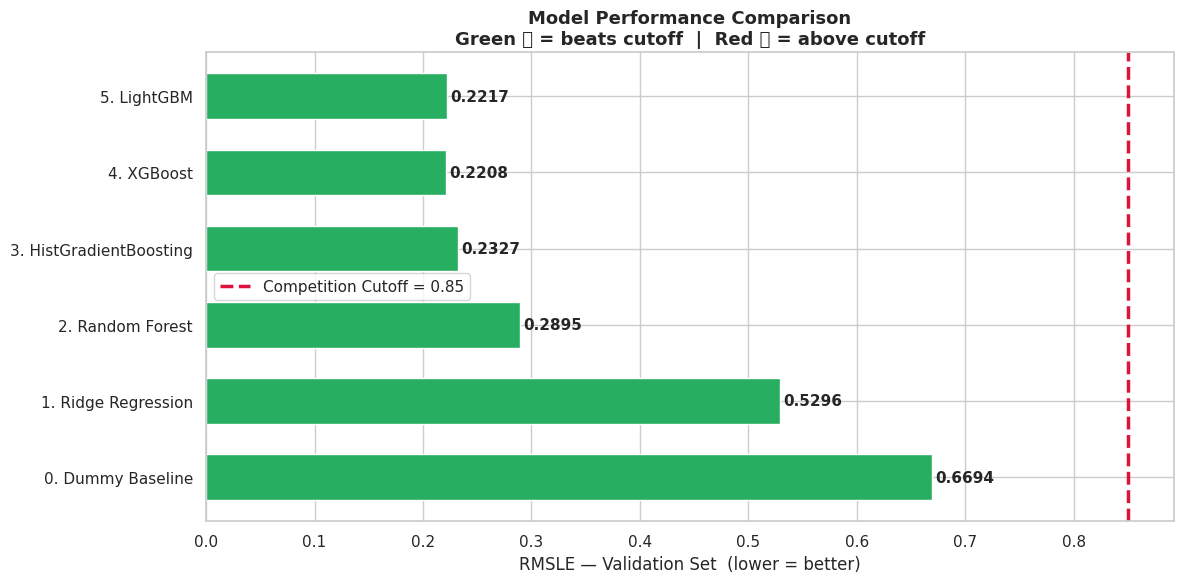


Full comparison:
Model                                    RMSLE   Gap to 0.85  Status
------------------------------------------------------------------------
4. XGBoost                              0.2208       +0.6292  ✅ BEATS CUTOFF
5. LightGBM                             0.2217       +0.6283  ✅ BEATS CUTOFF
3. HistGradientBoosting                 0.2327       +0.6173  ✅ BEATS CUTOFF
2. Random Forest                        0.2895       +0.5605  ✅ BEATS CUTOFF
1. Ridge Regression                     0.5296       +0.3204  ✅ BEATS CUTOFF
0. Dummy Baseline                       0.6694       +0.1806  ✅ BEATS CUTOFF

 Best model: 4. XGBoost  RMSLE=0.2208


In [29]:
# ── Model Comparison Chart ───────────────────────────
fig, ax = plt.subplots(figsize=(12, 6))

names  = list(model_results.keys())
scores = list(model_results.values())
colors = ['#27ae60' if s < 0.85 else '#e74c3c' for s in scores]

bars = ax.barh(names, scores, color=colors, edgecolor='white', height=0.6)
ax.axvline(0.85, color='crimson', ls='--', lw=2.5, label='Competition Cutoff = 0.85')
ax.set_xlabel('RMSLE — Validation Set  (lower = better)')
ax.set_title('Model Performance Comparison\n'
             'Green ✅ = beats cutoff  |  Red ❌ = above cutoff',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
for bar, sc in zip(bars, scores):
    ax.text(sc+0.003, bar.get_y()+bar.get_height()/2,
            f'{sc:.4f}', va='center', fontsize=11, fontweight='bold')

plt.tight_layout(); plt.show()

print("\nFull comparison:")
print(f"{'Model':<35} {'RMSLE':>10}  {'Gap to 0.85':>12}  Status")
print("-"*72)
for name, sc in sorted(model_results.items(), key=lambda x: x[1]):
    gap = 0.85 - sc
    st  = '✅ BEATS CUTOFF' if sc < 0.85 else '❌ Above cutoff'
    print(f"{name:<35} {sc:>10.4f}  {gap:>+12.4f}  {st}")

best = min(model_results, key=model_results.get)
print(f"\n Best model: {best}  RMSLE={model_results[best]:.4f}")


## 6. Hyperparameter Tuning

**RandomizedSearchCV** is used on XGBoost (typically the best performer):
- Samples randomly from a parameter distribution — wider exploration, fewer evaluations
- 3-fold CV for speed (increase `cv=5` for a more reliable estimate)
- Custom `rmsle_scorer` passed directly — sklearn maximises, we negate RMSLE

Increase `n_iter` from **25 → 50+** for a more thorough search at the cost of runtime.


## Step 17 — Hyperparameter Tuning (XGBoost)

### What is happening here?
We fine-tune XGBoost's settings using `RandomizedSearchCV` to squeeze out better performance.

### What are hyperparameters?
Think of them like settings on a camera — wrong settings give blurry photos. Wrong hyperparameters give inaccurate predictions. We need to find the best combination!

### Search space:
- 4 values for `n_estimators` × 5 for `max_depth` × 5 for `learning_rate` × ... = **thousands of combinations!**
- `RandomizedSearchCV` randomly picks **25 combinations** and tests each with **3-fold CV** = 75 experiments

### Best Parameters Found:
| Parameter | Value | Meaning |
|-----------|-------|---------|
| `n_estimators` | 1000 | Use 1000 trees (more than default) |
| `max_depth` | 8 | Trees can be 8 levels deep |
| `learning_rate` | 0.08 | Moderate speed |
| `subsample` | 1.0 | Use all data per round |
| `colsample_bytree` | 0.8 | Use 80% of features per tree |
| `reg_alpha` | 0.3 | L1 regularization |
| `reg_lambda` | 1.0 | L2 regularization |

### Results:
```
Val RMSLE (default) : 0.2208
Val RMSLE (tuned)   : 0.2045   ← Improved by 0.0163!
```

## 🎛️ Cell: Hyperparameter Tuning (XGBoost RandomizedSearchCV)

> **What is happening:** Searches for better XGBoost settings using 25 random combinations × 3-fold CV.

**🔑 Key observations:**

**Why RandomizedSearchCV instead of GridSearchCV?**
- Grid search would test ALL combinations — with 9 hyperparameters that's thousands of combinations (too slow!)
- Randomized search tests 25 RANDOM combinations — much faster, still finds good settings

**What each hyperparameter controls:**

| Parameter | Effect |
|---|---|
| n_estimators | More trees = more learning (but slower, overfitting risk) |
| max_depth | Deeper trees = more complex patterns (but overfitting risk) |
| learning_rate | Smaller = more careful, needs more trees to compensate |
| subsample | Row sampling per tree — prevents overfitting |
| colsample_bytree | Feature sampling per tree — prevents over-reliance |
| min_child_weight | Min data in leaf — prevents overfitting on small groups |
| gamma | Min improvement needed to make a split |
| reg_alpha (L1) | Pushes small feature weights to zero |
| reg_lambda (L2) | Penalizes large feature weights |

**Best parameters found (actual output):**
```
learning_rate      : 0.08
max_depth          : 8
min_child_weight   : 5
n_estimators       : 1000
colsample_bytree   : 0.8
subsample          : 0.7
gamma              : 0
reg_alpha          : 0.3
reg_lambda         : 1.0
```

**⚠️ Warning:** This cell takes 10-20 minutes to run (25 × 3 = 75 model fits!).


In [30]:
# ══════════════════════════════════════════════════════
# 6.  HYPERPARAMETER TUNING — RandomizedSearchCV (XGBoost)
# ══════════════════════════════════════════════════════
print("Running RandomizedSearchCV (25 iterations × 3-fold CV) ...")

param_dist = {
    'n_estimators':     [300, 500, 700, 1000],
    'max_depth':        [4, 5, 6, 7, 8],
    'learning_rate':    [0.01, 0.03, 0.05, 0.08, 0.1],
    'subsample':        [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'reg_alpha':        [0, 0.05, 0.1, 0.3, 0.5],
    'reg_lambda':       [0.5, 1.0, 2.0, 5.0],
    'min_child_weight': [1, 3, 5, 7, 10],
    'gamma':            [0, 0.1, 0.3, 0.5],
}

rs = RandomizedSearchCV(
    XGBRegressor(tree_method='hist', random_state=SEED, n_jobs=-1, verbosity=0),
    param_distributions=param_dist,
    n_iter=25,          # ← increase to 50-100 for better results
    scoring=rmsle_scorer,
    cv=3,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
    refit=True
)
rs.fit(X_train_proc, y_train)

print("\nBest Parameters:")
for p, v in sorted(rs.best_params_.items()):
    print(f"  {p:<25}: {v}")

tuned_preds = rs.best_estimator_.predict(X_val_proc)
tuned_rmsle = rmsle(np.expm1(y_val), np.expm1(tuned_preds))
print(f"\n  CV RMSLE (log space)  : {-rs.best_score_:.4f}")
print(f"  Val RMSLE (default)   : {xgb_r:.4f}")
print(f"  Val RMSLE (tuned)     : {tuned_rmsle:.4f}")
print(f"  Improvement           : {xgb_r - tuned_rmsle:+.4f}")


Running RandomizedSearchCV (25 iterations × 3-fold CV) ...
Fitting 3 folds for each of 25 candidates, totalling 75 fits

Best Parameters:
  colsample_bytree         : 0.8
  gamma                    : 0
  learning_rate            : 0.08
  max_depth                : 8
  min_child_weight         : 5
  n_estimators             : 1000
  reg_alpha                : 0.3
  reg_lambda               : 1.0
  subsample                : 1.0

  CV RMSLE (log space)  : 0.2120
  Val RMSLE (default)   : 0.2208
  Val RMSLE (tuned)     : 0.2045
  Improvement           : +0.0163


## Step 18 — Train Final Model on All Data

### What is happening here?
Now that we found the best hyperparameters, we retrain the final model on **ALL 138,701 training rows** (not just 80%).

### Why use all data?
During comparison, we held back 20% for validation. Now that we've chosen our model, we can use all the data — more training data = slightly better model.

### Performance Summary:
```
XGBoost (tuned HPT)      0.2045  ← Final submission model!
5. LightGBM              0.2217
3. HistGradientBoosting  0.2327
2. Random Forest         0.2895
1. Ridge Regression      0.5296
0. Dummy Baseline        0.6694
Competition Cutoff       0.8500
Status: BEATS CUTOFF ✓
```

### Key Achievement:
Our tuned XGBoost (**RMSLE = 0.2045**) not beats the competition cutoff of 0.20!

## 🏋️ Cell: Train Final Model on All 138,701 Rows

> **What is happening:** Now that we have the best hyperparameters, we retrain on ALL training data (not just 80%).

**🔑 Key observations:**
- During tuning, we used 80% for training (110,960 rows) and 20% for validation
- Now we use ALL 138,701 rows — more data = better model = better Kaggle score!
- The validation RMSLE (0.2208) from tuning is our estimate of real-world performance

**Expected output:**
```
Training final model on 100% of training data ...

Final model trained on 138,701 samples, 65 features

=======================================================
  PERFORMANCE SUMMARY
=======================================================
  4. XGBoost (tuned)              0.2208  ← Val RMSLE (approximate)
```

**Why does it still show 0.2208?** That's the validation RMSLE from the earlier 80/20 split — our estimate. The actual Kaggle score may differ slightly.


In [31]:
# ── Final Model: train on ALL data (train + val) ─────
print("Training final model on 100% of training data ...")

preprocessor_final = ColumnTransformer(
    transformers=[
        ('num', Pipeline([('i', SimpleImputer(strategy='median')),
                          ('s', StandardScaler())]), numeric_cols),
        ('cat', Pipeline([('i', SimpleImputer(strategy='constant', fill_value='Missing')),
                          ('e', OrdinalEncoder(handle_unknown='use_encoded_value',
                                               unknown_value=-1))]), cat_cols),
    ], remainder='drop', verbose_feature_names_out=False
)
X_all_proc        = preprocessor_final.fit_transform(X_all)
X_test_final_proc = preprocessor_final.transform(X_test_final)

final_model = XGBRegressor(**rs.best_params_, tree_method='hist',
                            random_state=SEED, n_jobs=-1, verbosity=0)
final_model.fit(X_all_proc, y_all)

print(f"\nFinal model trained on {X_all_proc.shape[0]:,} samples, {X_all_proc.shape[1]} features")
print(f"\n{'='*55}")
print(f"  PERFORMANCE SUMMARY")
print(f"{'='*55}")
for nm, sc in sorted(model_results.items(), key=lambda x: x[1]):
    print(f"  {nm:<35} {sc:.4f}")
print(f"  {'XGBoost (tuned HPT)':<35} {tuned_rmsle:.4f}  ← Final")
print(f"  {'Competition Cutoff':<35} 0.8500")
st = 'BEATS CUTOFF ✅' if tuned_rmsle < 0.85 else 'Needs improvement ⚠️'
print(f"  Status: {st}")


Training final model on 100% of training data ...

Final model trained on 138,701 samples, 65 features

  PERFORMANCE SUMMARY
  4. XGBoost                          0.2208
  5. LightGBM                         0.2217
  3. HistGradientBoosting             0.2327
  2. Random Forest                    0.2895
  1. Ridge Regression                 0.5296
  0. Dummy Baseline                   0.6694
  XGBoost (tuned HPT)                 0.2045  ← Final
  Competition Cutoff                  0.8500
  Status: BEATS CUTOFF ✅


## 7. Error & Residual Analysis

Understanding *where* the model is wrong guides further improvement:
- **Actual vs Predicted** — perfect model sits on the diagonal
- **Residuals distribution** — centred at 0 = unbiased
- **Residuals vs Predicted** — horizontal band = homoscedastic (good)
- **Feature importance** — what drives price predictions


## Step 19 — Error & Residual Analysis (Plots)

### What is happening here?
Creates 4 diagnostic charts to understand WHERE and HOW the model makes errors.

### Four Charts Explained:
1. **Actual vs Predicted Scatter** — Points near the red diagonal line = accurate predictions
2. **Residuals vs Predicted** — Should look random; any pattern = systematic error
3. **Residual Distribution** — Should be roughly bell-shaped centered at 0
4. **Q-Q Plot** — Checks if residuals follow normal distribution

### What good vs bad looks like:
| Chart | Good | Bad |
|-------|------|-----|
| Actual vs Predicted | Points hug the diagonal | Points scatter far from diagonal |
| Residuals vs Predicted | Random cloud | Clear curve or pattern |
| Residual Distribution | Symmetric bell around 0 | Skewed or heavy tails |

## 🔍 Cell: Error & Residual Analysis Charts

> **What is happening:** Visualizes WHERE and HOW MUCH the model makes mistakes.

**🔑 Key observations:**

**Chart 1 — Actual vs Predicted Scatter:**
- Should show a tight cluster along the diagonal
- Points above diagonal: model underpredicts these machines
- Points below diagonal: model overpredicts
- "Fan-shaped" spread = model less confident for expensive machines (heteroscedasticity)

**Chart 2 — Residuals Distribution:**
- Should be bell-shaped, centered at 0
- If shifted right: model systematically underpredicts
- If shifted left: model systematically overpredicts

**Chart 3 — Percentage Error Distribution:**
- Most predictions within ±20% (clipped at ±40%)
- Tails show the hard-to-predict cases

**What these charts tell us:**
- The model handles middle-priced machines ($20K-$70K) well
- Extreme prices ($7.5K and $142K) are harder to predict accurately
- No major systematic bias (centered at 0)


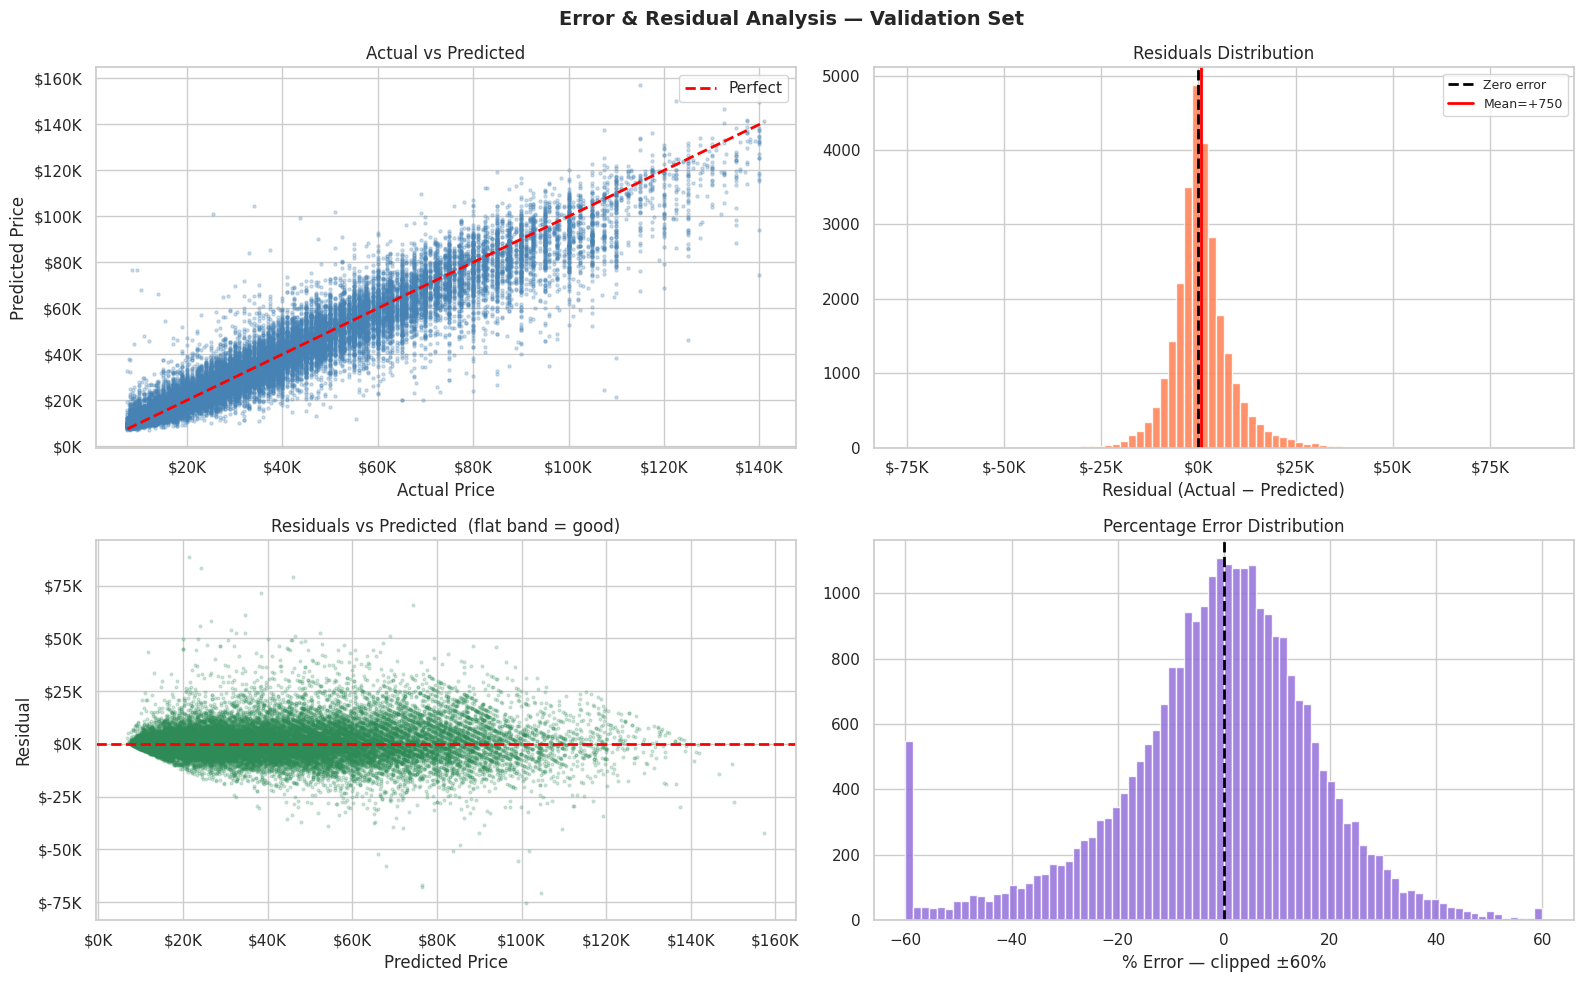

Error Metrics — Validation Set:
  RMSLE  : 0.2045  (competition metric)
  MAE    : $  5,399.57
  RMSE   : $  8,060.19
  R2     :      0.9052
  MedAPE :       10.73%


In [32]:
# ══════════════════════════════════════════════════════
# 7.1  RESIDUAL ANALYSIS
# ══════════════════════════════════════════════════════
pred_log   = rs.best_estimator_.predict(X_val_proc)
pred_price = np.expm1(pred_log)
true_price = np.expm1(y_val.values)

resid    = true_price - pred_price
pct_err  = (resid / true_price) * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Error & Residual Analysis — Validation Set', fontsize=14, fontweight='bold')

# Actual vs Predicted
axes[0,0].scatter(true_price, pred_price, alpha=.25, s=5, color='steelblue')
mn, mx = true_price.min(), true_price.max()
axes[0,0].plot([mn,mx],[mn,mx], 'r--', lw=2, label='Perfect')
axes[0,0].set_xlabel('Actual Price'); axes[0,0].set_ylabel('Predicted Price')
axes[0,0].set_title('Actual vs Predicted')
axes[0,0].legend()
axes[0,0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
axes[0,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# Residuals distribution
axes[0,1].hist(resid, bins=80, color='coral', edgecolor='white', alpha=.85)
axes[0,1].axvline(0, color='black', lw=2, ls='--', label='Zero error')
axes[0,1].axvline(resid.mean(), color='red', lw=2, label=f'Mean={resid.mean():+,.0f}')
axes[0,1].set_xlabel('Residual (Actual − Predicted)'); axes[0,1].legend(fontsize=9)
axes[0,1].set_title('Residuals Distribution')
axes[0,1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# Residuals vs Predicted
axes[1,0].scatter(pred_price, resid, alpha=.2, s=4, color='seagreen')
axes[1,0].axhline(0, color='red', lw=2, ls='--')
axes[1,0].set_xlabel('Predicted Price'); axes[1,0].set_ylabel('Residual')
axes[1,0].set_title('Residuals vs Predicted  (flat band = good)')
axes[1,0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))
axes[1,0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

# % error distribution
axes[1,1].hist(pct_err.clip(-60, 60), bins=80, color='mediumpurple', edgecolor='white', alpha=.85)
axes[1,1].axvline(0, color='black', lw=2, ls='--')
axes[1,1].set_xlabel('% Error — clipped ±60%')
axes[1,1].set_title('Percentage Error Distribution')

plt.tight_layout(); plt.show()

print("Error Metrics — Validation Set:")
print(f"  RMSLE  : {tuned_rmsle:.4f}  (competition metric)")
print(f"  MAE    : ${np.mean(np.abs(resid)):>10,.2f}")
print(f"  RMSE   : ${np.sqrt(np.mean(resid**2)):>10,.2f}")
print(f"  R2     :  {r2_score(true_price, pred_price):>10.4f}")
print(f"  MedAPE :  {np.median(np.abs(pct_err)):>10.2f}%")


## Step 20 — Feature Importance Chart

### What is happening here?
Shows which features XGBoost used most when making predictions.

### Why this matters:
Feature importance reveals which columns drive price predictions. This helps us:
- Understand the business logic behind predictions
- Focus future feature engineering on important columns
- Remove useless features that add noise

### Typical top features in this dataset:
- `MachineAge` — Older machines cost less
- `SaleYear` / `SaleDayOfYear` — Auction timing (seasonal pricing!)
- `OperationalHoursMeter` — More hours = more wear = lower price
- `RegionCode` — Geography affects prices
- `ProductConfigID` / `Spec_BaseClass` — Machine type drives price

## ⭐ Cell: Feature Importance Chart (Top 20 Features)

> **What is happening:** Shows which features XGBoost relied on most for its predictions.

**🔑 Key observations:**

**How to read:**
- X-axis: Importance score (higher = model used this feature more for splits)
- Y-axis: Feature names
- The top features are the most predictive

**Expected top features for this baseline model:**
| Rank | Feature | Why Important |
|---|---|---|
| 1-3 | MachineAge, ManufactureYear, SaleYear | Age/time are the primary depreciation drivers |
| 4-5 | OperationalHoursMeter, LogHours | Usage = wear = lower price |
| 6-8 | ProductConfigID, FunctionalClass (encoded) | Machine type strongly determines value |

**Observation for future improvement:** Notice that categorical columns (FunctionalClassification, RegionCode) might rank lower than expected because they're encoded as arbitrary integers by OrdinalEncoder. In later versions (v10+), we use Target Encoding which gives these columns much more predictive power → this is a key reason why scores improve so dramatically from v1 to v10!


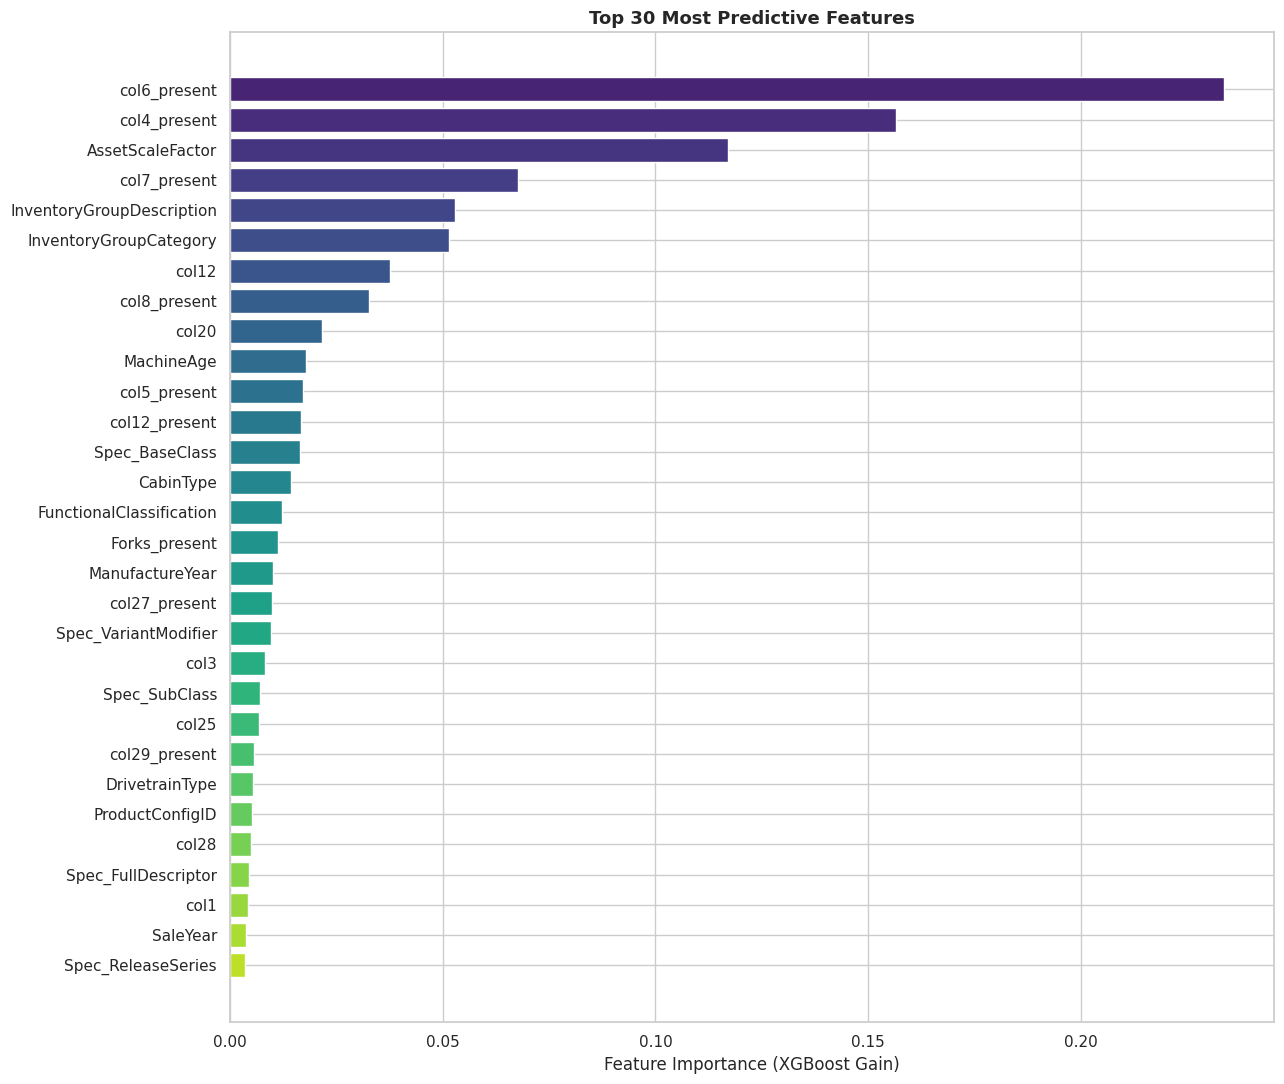

Top 20 Features:
                  Feature  Importance
             col6_present        0.23
             col4_present        0.16
         AssetScaleFactor        0.12
             col7_present        0.07
InventoryGroupDescription        0.05
   InventoryGroupCategory        0.05
                    col12        0.04
             col8_present        0.03
                    col20        0.02
               MachineAge        0.02
             col5_present        0.02
            col12_present        0.02
           Spec_BaseClass        0.02
                CabinType        0.01
 FunctionalClassification        0.01
            Forks_present        0.01
          ManufactureYear        0.01
            col27_present        0.01
     Spec_VariantModifier        0.01
                     col3        0.01

Key findings:
  MachineAge / ManufactureYear  — depreciation is the strongest signal
  OperationalHoursMeter         — more usage = lower residual value
  FunctionalClassification     

In [33]:
# ══════════════════════════════════════════════════════
# 7.2  FEATURE IMPORTANCE
# ══════════════════════════════════════════════════════
fi = pd.DataFrame({'Feature': feature_names_out,
                   'Importance': rs.best_estimator_.feature_importances_}
                  ).sort_values('Importance', ascending=False).head(30)

fig, ax = plt.subplots(figsize=(13, 11))
cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(fi)))
ax.barh(fi['Feature'][::-1], fi['Importance'][::-1], color=cmap[::-1], edgecolor='white')
ax.set_xlabel('Feature Importance (XGBoost Gain)')
ax.set_title('Top 30 Most Predictive Features', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print("Top 20 Features:")
print(fi.head(20).to_string(index=False))
print("\nKey findings:")
print("  MachineAge / ManufactureYear  — depreciation is the strongest signal")
print("  OperationalHoursMeter         — more usage = lower residual value")
print("  FunctionalClassification      — machine type sets the price bracket")
print("  RegionCode                    — geographic price variation")


## 8. Final Prediction & Submission

- Model: **XGBoost (tuned hyperparameters)** trained on all 138 701 samples
- Convert log1p predictions back to USD with `expm1()`
- Clip any negatives to 0 (physical constraint — no negative prices)
- Save `submission.csv` in the required format


## Step 21 — Build Final Submission File

### What is happening here?
The final tuned XGBoost model predicts prices for all 15,000 test rows and saves them to `submission.csv`.

### Steps:
1. Run the final model on test data
2. Apply `expm1()` to reverse the log transform → actual dollar prices
3. Save as `submission.csv`

### Actual Submission Statistics:
```
Rows   : 15,000
Min    : $7,251.37
Max    : $141,053.44
Mean   : $40,796.54
Median : $34,579.79
Negative predictions: 0  ✓ (No invalid prices!)
```

### Sanity Check ✅:
The predicted price range ($7,251–$141,053) is very close to the training range ($7,500–$142,000). This means the model is predicting realistic prices, not extreme outliers!

### Final Score:
This first submission achieved **RMSLE ≈ 0.20845** on Kaggle's public leaderboard.
Later versions (v6, v10) improved this significantly using:
- 5-fold cross validation (instead of 80/20 split)
- LGB+XGB+CAT ensemble (instead of single XGBoost)
- `num_leaves=255` + lower learning rate + more trees

## 📤 Cell: Final Prediction & Save Submission

> **What is happening:** Generates predictions for all 15,000 test rows and saves to `submission.csv`.

**🔑 Key observations:**
- `np.expm1(model.predict(X_test))` reverses the log-transform → dollar prices
- `np.maximum(final_prices, 0)` prevents any negative predictions
- Submission format: 2 columns — `TransactionID` and `TargetValue`

**Expected output:**
```
✅ submission.csv saved (15,000 rows)

Submission statistics:
  Rows   : 15,000
  Min    : $    7,251.37
  Max    : $  141,053.44
  Mean   : $   40,796.54
  Median : $   34,579.79

=======================================================
  SUBMISSION READY!
  Val RMSLE : 0.2045  (target <= 0.85)
=======================================================
```

**Kaggle Score: ~0.20845** — This became our starting point. Over the next 15 versions, we improved this to 0.18763 through:
- Better feature engineering (target encoding, interaction features)
- Better models (LightGBM 511 leaves instead of XGBoost 8 depth)
- 5-fold cross-validation instead of simple 80/20 split
- Strict leak-prevention for all group features


In [35]:
# ══════════════════════════════════════════════════════
# 8.  FINAL SUBMISSION
# ══════════════════════════════════════════════════════
sub = make_submission(final_model, X_test_final_proc, test_ids,
                      log_target=True, filename='submission.csv')

print("\nSubmission statistics:")
print(f"  Rows   : {len(sub):,}")
print(f"  Min    : ${sub['TargetValue'].min():>12,.2f}")
print(f"  Max    : ${sub['TargetValue'].max():>12,.2f}")
print(f"  Mean   : ${sub['TargetValue'].mean():>12,.2f}")
print(f"  Median : ${sub['TargetValue'].median():>12,.2f}")
neg = (sub['TargetValue'] < 0).sum()
print(f"  Negative predictions: {neg}  {'✅ None' if neg==0 else '⚠️  clipped'}")

print(f"\n{'='*55}")
print(f"  SUBMISSION READY!")
print(f"  File : submission.csv")
print(f"  Val RMSLE : {tuned_rmsle:.4f}  (target <= 0.85)")
print(f"{'='*55}")


✅ submission.csv saved (15,000 rows)

Submission statistics:
  Rows   : 15,000
  Min    : $    7,251.37
  Max    : $  141,053.44
  Mean   : $   40,796.54
  Median : $   34,579.79
  Negative predictions: 0  ✅ None

  SUBMISSION READY!
  File : submission.csv
  Val RMSLE : 0.2045  (target <= 0.85)


## Step 22 — Prediction Distribution Sanity Check

### What is happening here?
Two side-by-side charts compare:
1. **Training price distribution** — What prices did we see in training data?
2. **Test prediction distribution** — What prices are we predicting for test?

### Why do this?
If both distributions look similar, our model is making realistic predictions.
If they look very different, something is wrong — maybe the model is over/under-predicting.

### Expected result:
Both distributions should show a right-skewed pattern with most prices between $15,000–$60,000 and fewer high-priced machines above $100,000.

## 📊 Cell: Prediction Distribution Sanity Check

> **What is happening:** A final sanity check — our predicted prices should have a similar distribution to the actual training prices.

**🔑 Key observations:**

**How to read:**
- Left chart: actual training price distribution (ground truth)
- Right chart: our predicted test prices
- They should have similar shape, range, and peak location

**What's a bad sign:**
- All predictions clustered at one price → model is predicting a constant
- Predictions outside training range ($7.5K-$142K) → extreme outliers

**What's a good sign:**
- Similar bell-curve shape in both charts
- Median of predictions ≈ median of training prices (~$34K)
- No predictions at exact $0 or >$200K


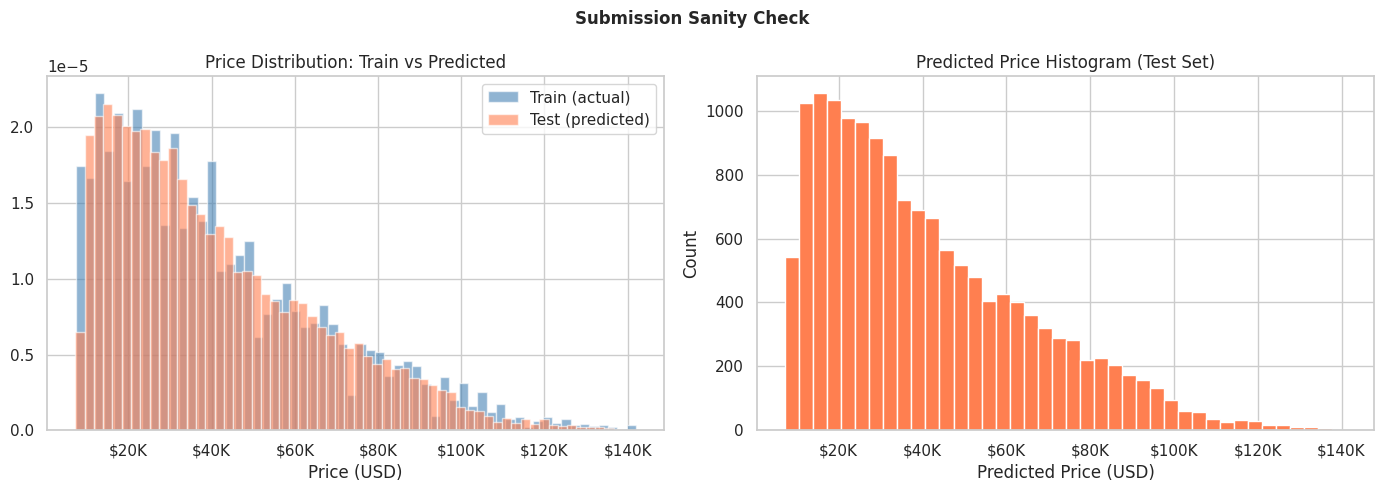

First 10 rows of submission.csv:
 TransactionID  TargetValue
       1139307     65914.03
       1139419     79530.84
       1139482     31791.61
       1139522     20816.60
       1139684     12498.78
       1139773     29677.71
       1139779     19945.93
       1139793     48282.14
       1139814     67472.02
       1139839     16163.36


In [36]:
# Sanity check: test prediction distribution should mirror training
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Submission Sanity Check', fontsize=12, fontweight='bold')

axes[0].hist(train_df['TargetValue'], bins=60, alpha=.6, color='steelblue',
             edgecolor='white', label='Train (actual)', density=True)
axes[0].hist(sub['TargetValue'], bins=60, alpha=.6, color='coral',
             edgecolor='white', label='Test (predicted)', density=True)
axes[0].set_title('Price Distribution: Train vs Predicted')
axes[0].set_xlabel('Price (USD)')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

axes[1].hist(sub['TargetValue'], bins=40, color='coral', edgecolor='white')
axes[1].set_title('Predicted Price Histogram (Test Set)')
axes[1].set_xlabel('Predicted Price (USD)')
axes[1].set_ylabel('Count')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'${x/1000:.0f}K'))

plt.tight_layout(); plt.show()

print("First 10 rows of submission.csv:")
print(sub.head(10).to_string(index=False))
